<div style="display: flex; align-items: center;">
    <img src="https://www.avantihnw.com/api/rp/w1200/h630/aHR0cHM6Ly93d3cuYXZhbnRpaG53LmNvbS9kYXRhL2VuLzEvMDEvZmVkYmMyMTItN2M3Zi00NTJjLWE4YmItMjQ3Nzk5OTRlMWUyLmpwZw===.jpg" alt="Image Alt Text" width="500" height="200" style="margin-right: 20px;">
    <div style="font-size: 60px;">
         <strong> 4<sup>th</sup> lab <strong>
    <div style="font-size: 40px;margin-right: 30px">
         <strong> MRI: DICOM Images <strong>
    </div>
</div>

<table>
  <tr>
    <td style="background-color: rgba(114, 147, 203, 0.9); font-size: 15px; color: white; padding: 20px;">
      <div style="font-size: 20px"> 
          <strong>XCT Module (2 x 2h)</strong><br>
      </div>  
      <ul>
        <li> <strong> Week 1 : visualisation and using of ready-to-use functions</strong> (2h)</li>
        <ul>
           <li> discover scikit image libary for XCT 
           <li> read files
           <li> plot profiles and global criteria
           <li> projections, sinograms
           <li> reconstruction with library functions (inverse Radon, FBP, SART)
        </ul>
        <br> 
        <li> <strong> Week 2 : code writing and analyses</strong> (2h)</li>
        <ul>
           <li> SART reconstruction code
           <li> FBP coding
           <li> compare with ready-to-use functions
           <li> use of global and local metrics to compare the results
        </ul>
    </td>
    <td style="background-color: rgba(225, 151, 76, 0.7); font-size: 15px; color: white; padding: 20px; vertical-align: top;">
    <div style="font-size: 20px"> 
        <strong> MRI Module (2 x 2h)</strong><br>
    </div> 
    <ul>
        <li> <strong> Week 3 : visualisation and using of ready-to-use functions</strong> (2h)</li>
        <ul>
           <li> read files, analyse the data and the image content
           <li> using DICOM
        </ul>
        <br> 
        <li> <strong> Week 4 : Explore 3D images, windows and views </strong> (2h)</li>
        <li> using NIfTI images
    </td>
    <td style="background-color: rgba(132, 186, 91, 0.8); font-size: 15px; color: white; padding: 20px; vertical-align: top;">
    <div style="font-size: 20px"> 
      <strong> Numerisation Module (2 x 2h)</strong><br>
    </div> 
      <ul>
        <li> <strong> Week 5 : depth map exploration </strong> (2h)</li>
        <br> 
        <li> <strong> Week 6 : point cloud and mesh understanding</strong> (2h)</li>
    </td>
  </tr>
</table>


<div style="display: flex; align-items: center;">
    <img src="https://img.freepik.com/premium-vector/warning-signs-high-voltage-hazard-isolated-white-background_68708-427.jpg?w=2000" alt="Image Alt Text" width="50" height="50" style="margin-right: 20px;">
    <div style="font-size: 15px;margin-right: 30px">
            Each lab must be completed before the beginning of the other lab session. 
        <br> 
          <strong>Don't forget to entitle your .ipynb file with your name and surname. <strong>
        <br> 
         The final submission of the first module has to be done <strong> by Thursday 17<sup> th</sup> October before 10 am.</strong>
    </div>
</div>

<table>
      <td style="border-left: 3px solid rgba(114, 147, 203, 0.9); background-color: rgba(114, 147, 203, 0.1); font-size: 15px; color: blakc; padding-left: 30px;">
        Don't forget to legend your figures and graphs. Interpretations are expected and must by short but comprehensive.  
      </td>
</table>

#### Contact : anna-louise.brun@u-bordeaux.fr

We saw two types of normalizations last week. There is another method which uses two metadata fields of the DICOM

#### **METHOD 2:** Windowing

1. Load the `sample_mri.dcm` and get the WindowWidth and WindowCenter values. These two vaues give you the intensities of interest in the scan.
2. Use the center and the width to find the range of intensities that are of interest in the MRI. 
3. Use `np.clip` to discard the intensities that lie beyond the range that you calculated above
4. Use the min-max method to normalize the values to [0, 255]
5. Plot the final image and the corresponding colorbar

WindowCenter = 3041, WindowWidth = 6083  ->  window = [-0.5, 6082.5]
intensities present in the image: [0, 1335]
number of pixels modified by the clipping: 0
windowed image range: [0.02, 55.98] -> only 57 distinct grey levels out of 256 are used
Min-Max of the clipped data == Lab 3 Min-Max (window contains all the data): True
max difference with the DICOM-standard formula: 0.009 grey level


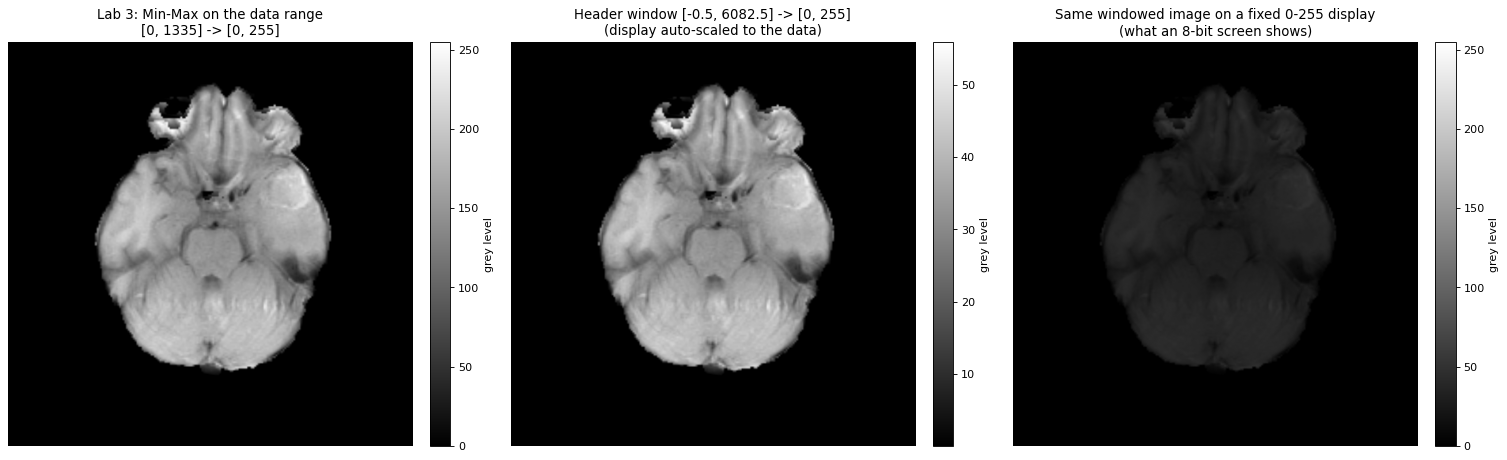

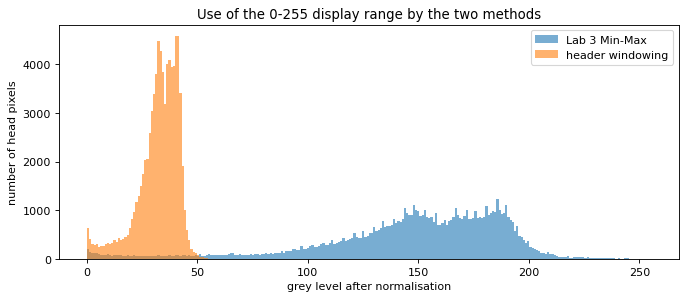

In [1]:
#CODE
# ANSWER: windowing with the WindowCenter / WindowWidth stored in the DICOM header
import numpy as np
import matplotlib.pyplot as plt
import pydicom

plt.rcParams["figure.dpi"] = 80          # keeps the notebook file size reasonable

ds = pydicom.dcmread("sample_mri.dcm")
# Modality LUT (Rescale Slope / Intercept): identity for this file, applied for correctness
img_dcm = ds.pixel_array.astype(np.float64) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)

def first_value(v):
    """WindowCenter/WindowWidth may contain several values (several presets): take the first one."""
    return float(v[0]) if isinstance(v, pydicom.multival.MultiValue) else float(v)

# 1. window centre and width
wc, ww = first_value(ds.WindowCenter), first_value(ds.WindowWidth)
# 2. range of intensities of interest
w_min, w_max = wc - ww / 2, wc + ww / 2
print(f"WindowCenter = {wc:.0f}, WindowWidth = {ww:.0f}  ->  window = [{w_min:.1f}, {w_max:.1f}]")
print(f"intensities present in the image: [{img_dcm.min():.0f}, {img_dcm.max():.0f}]")
# 3. discard (clip) the intensities outside the window
img_clip = np.clip(img_dcm, w_min, w_max)
print("number of pixels modified by the clipping:", int(np.sum(img_clip != img_dcm)))
# 4. Min-Max normalisation to [0, 255] using the window limits as min and max
img_win = (img_clip - w_min) / (w_max - w_min) * 255
img_win_u8 = np.round(img_win).astype(np.uint8)
print(f"windowed image range: [{img_win.min():.2f}, {img_win.max():.2f}] "
      f"-> only {np.unique(img_win_u8).size} distinct grey levels out of 256 are used")

# Comparisons
img_mm = (img_dcm - img_dcm.min()) / (img_dcm.max() - img_dcm.min()) * 255            # Lab 3 Min-Max
img_clip_mm = (img_clip - img_clip.min()) / (img_clip.max() - img_clip.min()) * 255    # Min-Max of the clipped data
print("Min-Max of the clipped data == Lab 3 Min-Max (window contains all the data):", np.allclose(img_clip_mm, img_mm))
# exact linear VOI LUT of the DICOM standard (PS3.3 C.11.2.1.2.1)
img_std = np.clip(((img_dcm - (wc - 0.5)) / (ww - 1) + 0.5) * 255, 0, 255)
print(f"max difference with the DICOM-standard formula: {np.abs(img_std - img_win).max():.3f} grey level")

# 5. plots with colour bars
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
panels = [(img_mm, "Lab 3: Min-Max on the data range\n[0, 1335] -> [0, 255]", {}),
          (img_win, f"Header window [{w_min:.1f}, {w_max:.1f}] -> [0, 255]\n(display auto-scaled to the data)", {}),
          (img_win, "Same windowed image on a fixed 0-255 display\n(what an 8-bit screen shows)", dict(vmin=0, vmax=255))]
for ax, (data, title, kw) in zip(axes, panels):
    im = ax.imshow(data, cmap="gray", **kw); ax.set_title(title); ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="grey level")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 3.8))
plt.hist(img_mm[img_dcm > 0], bins=256, range=(0, 255), alpha=0.6, label="Lab 3 Min-Max")
plt.hist(img_win[img_dcm > 0], bins=256, range=(0, 255), alpha=0.6, label="header windowing")
plt.xlabel("grey level after normalisation"); plt.ylabel("number of head pixels"); plt.legend()
plt.title("Use of the 0-255 display range by the two methods"); plt.show()

Comment on the range of intensities in the colorbar with this method and the other from the previous lab

1. **ANSWER**
   - **Header window:** WindowCenter = 3041 and WindowWidth = 6083 give the range of interest $[C - W/2,\ C + W/2] = [-0.5,\ 6082.5]$. The image only contains values in [0, 1335], so the window is about 4.6 times wider than the data and **`np.clip` changes no pixel at all**.
   - **Colour-bar range after windowing:** the window limits are mapped to 0 and 255, so the brightest pixel (1335) only reaches $(1335 + 0.5)/6083 \times 255 \approx 56$. The windowed image therefore spans **[0, 56]**: only 57 of the 256 available grey levels (about 22 % of the display range) are used.
   - **Lab 3 Min-Max, for comparison:** the colour bar spans **[0, 255]**. The actual data minimum and maximum are mapped to black and white, and almost all grey levels are used.
   - **Effect on the display:** with `imshow` in automatic mode, both images look identical, because matplotlib stretches [0, 56] over the whole colour map; only the colour bar reveals the difference. On a real 8-bit display with a fixed [0, 255] scale (third panel), the windowed image is very dark and has low contrast. The histogram shows that the windowed values are squeezed into the first fifth of the grey scale.
   - **Why Min-Max of the clipped data gives the Lab 3 result:** applying Min-Max to the clipped data with *its own* min and max gives exactly the Lab 3 result (`np.allclose` returns `True`), because nothing was clipped. Windowing only differs from Min-Max when the window limits themselves are used as min and max in step 4, as done here. Our result agrees with the exact linear formula of the DICOM standard (PS3.3 C.11.2.1.2.1) to within 0.01 grey level.
   - **Interpretation:** the stored window is not adapted to this image. The image is `DERIVED/SECONDARY`, and every slice of the series has a different centre (3022–3624) while its maximum is only 1322–2043, so the window seems to come from a different intensity scale than the stored pixel values. Windowing is useful when the window is *narrower* than the data: it then spreads a chosen intensity range over all 256 grey levels and increases the contrast of the tissues of interest. Values outside the window are saturated, and that clipping cannot be undone on the display. This is shown on the 3D image in the next sections. MRI intensities have no absolute units (unlike Hounsfield units in CT), so a useful window has to be adapted to each image.

A small caveat for this exercise is, as previously discussed, the images we use in this lab are already pre-processed. So you may not notice a visible change in the image while viewing it. Plot the colorbar to see the effect of this normalization. In the further sections we will work with 3D images where you will be able to vizualize the difference.

<div style="display: flex; align-items: center;">
    <img src="https://upload.wikimedia.org/wikipedia/commons/0/03/T1-weighted-MRI.png" alt="Image Alt Text" width="100" height="100" style="margin-right: 20px;">
    <div style="font-size: 20px;margin-right: 30px">
         <strong> Reading and Understanding NIfTI <strong>
    </div>
</div>

## NIfTI: Neuroimaging Informatics Technology Initiative

It is a data format for the storage of MRI and other medical images

Ref: https://neuraldatascience.io/8-mri/nifti.html

The goal of this assignment is to be able to open, display and reader the header information from a `.nii` file.

NIfTI-1, DICOM, and ANALYZE are three distinct formats used in the field of medical imaging, and they serve different purposes and have different characteristics. Here's a comparison of these formats:

#### Purpose:

- NIfTI-1: NIfTI-1 is primarily used for neuroimaging data, particularly in the context of MRI and fMRI data. It is designed to store and share imaging data in a standardized and flexible manner.

- DICOM: DICOM (Digital Imaging and Communications in Medicine) is a widely used format in medical imaging for storing and exchanging various types of medical images, not limited to neuroimaging. It includes a broader range of medical imaging modalities, such as X-rays, CT scans, ultrasound, and more.

- ANALYZE: ANALYZE is an older format primarily used for storing 3D and 4D (spatiotemporal) medical imaging data. It was widely used in the past but has been largely replaced by NIfTI-1 and DICOM due to their improved features and standards.

#### Metadata and Flexibility:

- NIfTI-1: NIfTI-1 provides a standardized header that includes metadata about the data, making it easier to interpret and work with. It also allows for optional extensions to store additional information, increasing its flexibility.

- DICOM: DICOM is highly standardized and includes extensive metadata for various types of medical images. It is designed to accommodate a wide range of medical imaging equipment and modalities, making it highly flexible.

- ANALYZE: ANALYZE has a simpler header compared to NIfTI-1 and DICOM, which can limit its ability to capture extensive metadata. It is less flexible in comparison.

#### Coordinate System:

- NIfTI-1: NIfTI-1 defines a standard coordinate system for data, which helps ensure consistency when working with brain images.

- DICOM: DICOM does not prescribe a specific coordinate system. Instead, it includes patient position and orientation information that can vary between different modalities and vendors.

- ANALYZE: ANALYZE does not define a standard coordinate system either. It relies on basic orientation information in the header.

#### Compression:

- NIfTI-1: NIfTI-1 files can be optionally compressed using GZIP, which can help reduce file sizes.

- DICOM: DICOM files can also be compressed, often using lossless compression methods like JPEG-LS or JPEG2000.

- ANALYZE: ANALYZE files typically do not include built-in compression options.

In summary, NIfTI-1, DICOM, and ANALYZE are three distinct formats used in medical imaging, with NIfTI-1 being specifically tailored to neuroimaging, DICOM being a broader standard for medical imaging, and ANALYZE being an older format that has been largely replaced by NIfTI-1 and DICOM in modern medical imaging practice. The choice of format depends on the specific imaging modality and the needs of the research or clinical application.

<div style="display: flex; align-items: center;">
    <img src="https://nipy.org/nibabel/_static/nibabel-logo.svg" alt="Image Alt Text" width="100" height="100" style="margin-right: 20px;">
    <div style="font-size: 20px;margin-right: 15px">
           We will use <strong>Nibabel</strong>. 
    </div>
</div>

Install nibabel library locally. (https://nipy.org/nibabel/)

In [2]:
# Install
# ANSWER: nibabel is installed with pip (only once; restart the kernel afterwards):
#   %pip install nibabel
# It is already installed in this environment, which we check instead of re-installing:
import importlib.util
print("nibabel available:", importlib.util.find_spec("nibabel") is not None)

nibabel available: True


In [3]:
import nibabel as nib
# ANSWER: other imports used in this part
from scipy import ndimage
print("nibabel version:", nib.__version__)

nibabel version: 5.3.2


There is a compressed `.nii` file provided along with the notebook. 
1. Read this NIfTI file. (Ensure it is saved in the same folder as this notebook)

In [4]:
# ANSWER: template completed
img = nib.load("sample_MRI.nii.gz") #use nibabel to read the file

You will notice that the image you read is an object of a custom class. 

In [5]:
print(type(img))

<class 'nibabel.nifti1.Nifti1Image'>



2. Similar to DICOM, these files also have a header with some metadata provided. Explore a way to access all the keys and identify some interesting ones

Extra reference: Qform, Sform : https://gru.stanford.edu/doku.php/mrtools/coordinatetransforms for some info about some of the fields (if you are curious about it)

In [6]:
#CODE
# ANSWER: header keys and values
header = img.header
print("Header class:", type(header))
print("Number of fields:", len(header.keys()))
print("Keys:", list(header.keys()))
print()
print(header)

Header class: <class 'nibabel.nifti1.Nifti1Header'>
Number of fields: 43
Keys: ['sizeof_hdr', 'data_type', 'db_name', 'extents', 'session_error', 'regular', 'dim_info', 'dim', 'intent_p1', 'intent_p2', 'intent_p3', 'intent_code', 'datatype', 'bitpix', 'slice_start', 'pixdim', 'vox_offset', 'scl_slope', 'scl_inter', 'slice_end', 'slice_code', 'xyzt_units', 'cal_max', 'cal_min', 'slice_duration', 'toffset', 'glmax', 'glmin', 'descrip', 'aux_file', 'qform_code', 'sform_code', 'quatern_b', 'quatern_c', 'quatern_d', 'qoffset_x', 'qoffset_y', 'qoffset_z', 'srow_x', 'srow_y', 'srow_z', 'intent_name', 'magic']

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : np.bytes_(b'')
db_name         : np.bytes_(b'')
extents         : 0
session_error   : 0
regular         : np.bytes_(b'r')
dim_info        : 0
dim             : [  3 160 256 256   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype 

In [7]:
# ANSWER: interpretation of the most useful fields
print("dim            :", header["dim"], "-> ndim =", header["dim"][0], ", shape =", tuple(header["dim"][1:header["dim"][0] + 1]))
print("datatype/bitpix:", header.get_data_dtype(), "/", header["bitpix"], "bits")
print("pixdim         :", header["pixdim"], "-> qfac =", header["pixdim"][0], ", voxel size =", header["pixdim"][1:4])
print("xyzt_units     :", header["xyzt_units"], "->", header.get_xyzt_units())
print("scl_slope/inter:", header["scl_slope"], header["scl_inter"], "(NaN or 0 -> no intensity scaling)")
print("qform_code     :", header["qform_code"], "| sform_code:", header["sform_code"], "(1 = scanner coordinates)")
print("magic          :", header["magic"], "(n+1 = single .nii file, header + data)")
print("\nAffine (voxel indices -> world coordinates in mm), from the sform:")
print(np.round(img.affine, 3))
print("Orientation of the voxel axes (nib.aff2axcodes):", nib.aff2axcodes(img.affine))
print("Voxel (0,0,0) is at", np.round(img.affine @ [0, 0, 0, 1], 1)[:3], "mm;",
      "centre voxel is at", np.round(img.affine @ [80, 128, 128, 1], 1)[:3], "mm")

dim            : [  3 160 256 256   1   1   1   1] -> ndim = 3 , shape = (np.int16(160), np.int16(256), np.int16(256))
datatype/bitpix: float32 / 32 bits
pixdim         : [-1.          0.99999994  1.          0.99999994  0.          0.
  0.          0.        ] -> qfac = -1.0 , voxel size = [0.99999994 1.         0.99999994]
xyzt_units     : 2 -> ('mm', 'unknown')
scl_slope/inter: nan nan (NaN or 0 -> no intensity scaling)
qform_code     : 1 | sform_code: 1 (1 = scanner coordinates)
magic          : np.bytes_(b'n+1') (n+1 = single .nii file, header + data)

Affine (voxel indices -> world coordinates in mm), from the sform:
[[-9.98000e-01 -5.00000e-02 -4.30000e-02  8.83870e+01]
 [-5.00000e-02  9.99000e-01 -0.00000e+00 -1.20314e+02]
 [-4.30000e-02 -2.00000e-03  9.99000e-01 -1.16320e+02]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]
Orientation of the voxel axes (nib.aff2axcodes): ('L', 'A', 'S')
Voxel (0,0,0) is at [  88.4 -120.3 -116.3] mm; centre voxel is at [-3.3  3.5  7.8] 

Comment

**ANSWER (comment on the header)**

The NIfTI-1 header is a fixed 348-byte structure (`sizeof_hdr` = 348) with **43 fields**, listed by `header.keys()`. The most interesting fields:

| Field | Value | Meaning |
|---|---|---|
| `dim` | [3, 160, 256, 256, 1, 1, 1, 1] | `dim[0]` = 3 dimensions; size 160 × 256 × 256 (the unused 4th–7th dimensions, e.g. time, are 1) |
| `datatype` / `bitpix` | float32 / 32 | type of the stored voxel values |
| `pixdim` | [−1, 1.0, 1.0, 1.0, 0, …] | voxel size along x, y, z = **1 mm isotropic**; `pixdim[0]` = qfac = −1 gives the handedness used by the qform |
| `xyzt_units` | 2 | spatial unit = mm (code 2); time unit not set |
| `scl_slope` / `scl_inter` | NaN / NaN | no intensity scaling: the stored values are used as they are |
| `cal_min` / `cal_max` | 0 / 0 | no recommended display range (the NIfTI equivalent of a DICOM window is not set) |
| `qform_code` / `sform_code` | 1 / 1 ("scanner") | both transforms map voxel indices to scanner coordinates in mm |
| `quatern_b,c,d`, `qoffset_x,y,z` | quaternion + offsets | **qform**: rigid rotation + translation (+ voxel size) |
| `srow_x`, `srow_y`, `srow_z` | three rows of a 4 × 4 matrix | **sform**: general affine; used by nibabel for `img.affine` |
| `magic` | `n+1` | single-file `.nii` (header and data together; here gzip-compressed `.nii.gz`) |
| `slice_code`, `slice_duration`, `toffset`, `dim_info` | 0 / unknown | slice-timing information, only relevant for fMRI |
| `descrip`, `aux_file`, `intent_*` | empty / none | no description; plain image, not a statistical map |
| `data_type`, `db_name`, `extents`, `session_error`, `regular`, `glmax`, `glmin` | unused | legacy fields of the older ANALYZE 7.5 format, kept for backward compatibility |

The **affine** is close to diag(−1, 1, 1) plus small rotations of about 2–3° (the off-diagonal terms ≈ 0.04–0.05). `nib.aff2axcodes` returns **('L', 'A', 'S')**: the first index increases towards the patient's **L**eft, the second towards **A**nterior and the third towards **S**uperior. The centre voxel lies a few mm from the origin of the scanner coordinate system. This orientation information is what tells us which array axis corresponds to which anatomical view (next sections).

Compared with DICOM, the NIfTI header is minimal. It stores the geometry explicitly (voxel size and affine in a single file for the whole 3D volume), but no patient identity and no acquisition parameters such as TE, TR or field strength. This makes it convenient and anonymous for research pipelines, but less informative clinically.

The header also has some methods that you can use to get extra data. Try the following code and observe what they might be useful for?


Note: MRI is 3D and fMRI is (3D + time). This might affect what you see as output

In [8]:
header_object = img.header
print(header_object.get_zooms())
print(header_object.get_xyzt_units())

(np.float32(0.99999994), np.float32(1.0), np.float32(0.99999994))
('mm', 'unknown')


**ANSWER (what the two header methods are useful for)**

- **`get_zooms()`** returns the **voxel size along each axis**, read from `pixdim[1:4]`: (0.99999994, 1.0, 0.99999994), i.e. 1 mm × 1 mm × 1 mm (0.99999994 is float32 rounding of 1). It returns 3 values because the image is 3D (`dim[0] = 3`). For a 4D fMRI series it returns 4 values, the 4th being the **repetition time TR** (the time between two volumes).
- **`get_xyzt_units()`** decodes the `xyzt_units` field: **('mm', 'unknown')**. Spatial dimensions are in millimetres; the time unit is "unknown" because this volume has no time dimension. For fMRI it would typically be 'sec' or 'msec'.
- **Uses:**
  - converting voxel indices to physical distances, areas and volumes (here one voxel = 1 mm³, so the volume of a structure in mm³ equals its number of voxels);
  - displaying slices with the correct aspect ratio (here voxels are isotropic, so no correction is needed);
  - resampling and registering images of different resolutions;
  - reading the temporal sampling (TR) of fMRI data, needed for filtering and for building the statistical model.

  The units remove any ambiguity (mm vs m vs µm, s vs ms).

3. Access the data from the object and identify the type and shape of data. 
4. Is the acquisition shape of this MRI a cube? (look at the dimensions of the data and Comment)

In [9]:
#CODE
# ANSWER: access the data, its type and its shape
data = img.get_fdata()                       # floating-point array (float64 by default)
print("type of data       :", type(data))
print("dtype in memory    :", data.dtype, "| dtype stored in the file:", img.get_data_dtype())
print("shape              :", data.shape, "| ndim:", data.ndim, "| number of voxels:", data.size)
print("voxel size (mm)    :", np.round(header.get_zooms(), 3))
print("field of view (mm) :", np.round(np.array(data.shape) * np.array(header.get_zooms()), 1))
print("intensity range    :", data.min(), "to", data.max(), "| non-zero voxels: %.1f %%" % (100 * np.mean(data > 0)))
print("memory (float64)   : %.1f MB" % (data.nbytes / 1e6))

type of data       : <class 'numpy.ndarray'>
dtype in memory    : float64 | dtype stored in the file: float32
shape              : (160, 256, 256) | ndim: 3 | number of voxels: 10485760
voxel size (mm)    : [1. 1. 1.]
field of view (mm) : [160. 256. 256.]
intensity range    : 0.0 to 4785.0 | non-zero voxels: 30.1 %
memory (float64)   : 83.9 MB


Comment

**ANSWER**

**3. Type and shape of the data.**
- `img.get_fdata()` returns a **`numpy.ndarray` of `float64`**. nibabel converts to float64 by default, and would also apply `scl_slope`/`scl_inter` if they were set. The values are stored in the file as **`float32`** (`img.get_data_dtype()`). `img.dataobj` is a lazy proxy, so the data are only read from disk when needed.
- The shape is **(160, 256, 256)**, i.e. 10 485 760 voxels (about 84 MB in float64).
- Intensities range from 0 to 4785; only 30 % of the voxels are non-zero. The rest is air and an exactly-zero region at the inferior end of the volume (visible as a straight cut in the slices below), where the volume has been cropped.

**4. Is the acquisition shape a cube?** **No.**
- The voxels are cubes (isotropic 1 × 1 × 1 mm), but the matrix is 160 × 256 × 256. The field of view is therefore a rectangular box of **160 mm × 256 mm × 256 mm**, shorter along the first axis, which is the left–right axis (orientation code 'L').
- This is consistent with a 3D T1-weighted acquisition with a sagittal slab (the head is narrower from left to right than from front to back or from top to bottom, so fewer partitions are needed in that direction).
- Because the voxels are isotropic, all three views have the same 1 mm in-plane resolution. However, sagittal slices are 256 × 256 while coronal and axial slices are 160 × 256 (non-square).

### Visualizing the Slices

Unlike DICOM the .nii image is for MRI is a 3D image. 

1. Can you list the 3 types of views that we have for neuroimaging? (eg Saggital etc..
.)

ANSWER

**ANSWER: 1.** The three standard anatomical views (planes) in neuroimaging:
- **Sagittal** plane: vertical plane that separates **left from right** (side view). The mid-sagittal plane divides the brain into its two hemispheres.
- **Coronal** (frontal) plane: vertical plane that separates **anterior (front) from posterior (back)** (face-on view).
- **Axial** (transverse or horizontal) plane: horizontal plane that separates **superior (top) from inferior (bottom)**. By radiological convention it is viewed from the feet.

For this volume, the orientation codes ('L', 'A', 'S') give `data[i, :, :]` = **sagittal**, `data[:, j, :]` = **coronal** and `data[:, :, k]` = **axial** slices.


As we have a 3D image, we need to choose one slice to visualize at a time. 

2. Choose any slice from the x-axis (first index) of your data and plot it using `matplotlib`. If the view is rotated use `ndimage.rotate` to correct the orientation of the matrix
3. Plot the same slice for the 3 different views (choose the same index slice for the 3 dimensions of the matrix). Use caption to name the views correctly

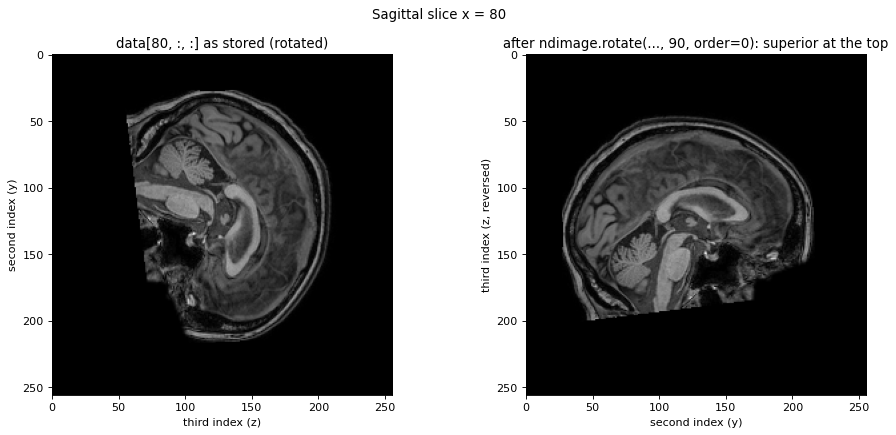

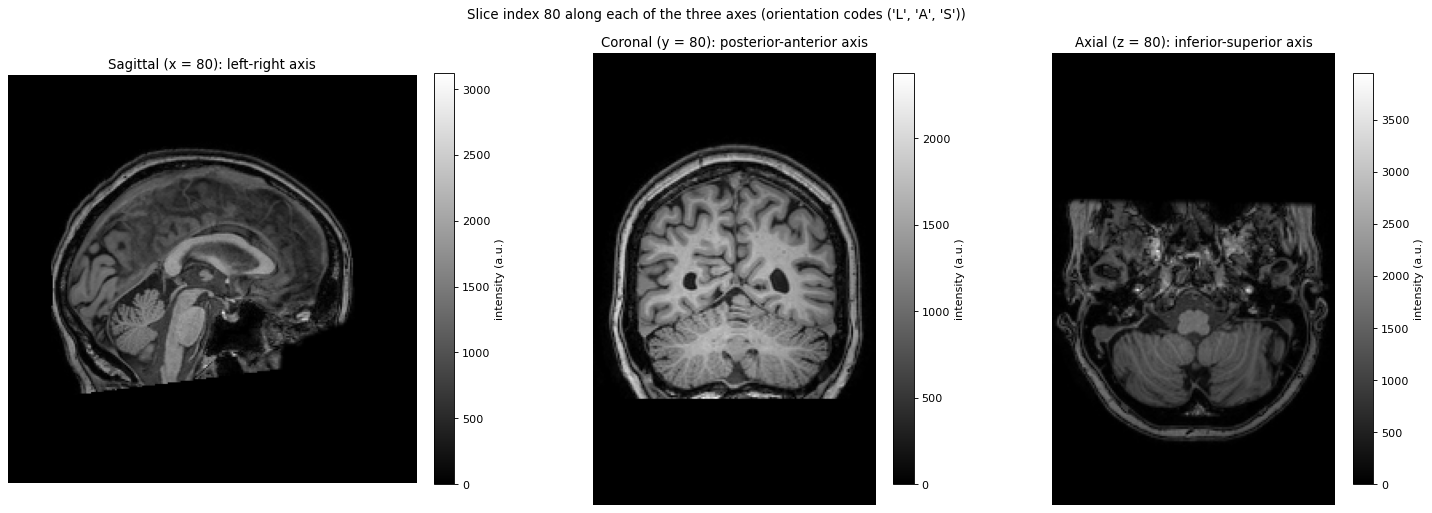

ndimage.rotate(., 90, order=0) identical to np.rot90(.): True


In [10]:
# CODE
# ANSWER
idx = 80                                    # same index along the three axes (valid for all: 80 < 160)

# 2. slice along the x-axis (first index) -> sagittal view
sag = data[idx, :, :]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
axes[0].imshow(sag, cmap="gray"); axes[0].set_title(f"data[{idx}, :, :] as stored (rotated)")
axes[0].set_xlabel("third index (z)"); axes[0].set_ylabel("second index (y)")
axes[1].imshow(ndimage.rotate(sag, 90, order=0), cmap="gray"); axes[1].set_title("after ndimage.rotate(..., 90, order=0): superior at the top")
axes[1].set_xlabel("second index (y)"); axes[1].set_ylabel("third index (z, reversed)")
plt.suptitle(f"Sagittal slice x = {idx}"); plt.tight_layout(); plt.show()

# 3. same index along the three axes -> three anatomical views
views = {"Sagittal (x = %d): left-right axis" % idx: data[idx, :, :],
         "Coronal (y = %d): posterior-anterior axis" % idx: data[:, idx, :],
         "Axial (z = %d): inferior-superior axis" % idx: data[:, :, idx]}
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, (name, sl) in zip(axes, views.items()):
    im = ax.imshow(ndimage.rotate(sl, 90, order=0), cmap="gray")
    ax.set_title(name); ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="intensity (a.u.)")
plt.suptitle(f"Slice index {idx} along each of the three axes (orientation codes {nib.aff2axcodes(img.affine)})")
plt.tight_layout(); plt.show()
# order=0: no spline interpolation, so a 90-degree rotation is exact (identical to np.rot90)
print("ndimage.rotate(., 90, order=0) identical to np.rot90(.):", np.array_equal(ndimage.rotate(sag, 90, order=0), np.rot90(sag)))

**ANSWER (interpretation)**
- **Orientation:** `data[80, :, :]` is stored with the antero-posterior axis along the rows and the inferior→superior axis along the columns. Displayed directly, the head therefore lies on its side. `ndimage.rotate(…, 90)` (counter-clockwise) puts the superior direction at the top. `order=0` (no spline interpolation) makes the 90° rotation exact, identical to `np.rot90`. The same rotation corrects all three views:
  - sagittal: anterior is on the right;
  - coronal and axial: the patient's right is on the left of the image (radiological convention);
  - axial: anterior is at the top.
- **Same index, three different anatomical positions:** the axes have different lengths, so index 80 does not mean the same thing in each view.
  - **Sagittal x = 80** is the centre of the 160-voxel axis, i.e. the **mid-sagittal plane**: corpus callosum, brainstem and cerebellar vermis are visible.
  - **Coronal y = 80** is 48 mm posterior to the centre of the 256-voxel axis: occipital horns of the lateral ventricles and the cerebellum.
  - **Axial z = 80** is a low slice through the posterior fossa: cerebellum, pons and temporal lobes.
- **Cropping:** the straight cut seen in the three views (a plane below which the volume is exactly 0, slightly tilted because the acquisition is oblique) is the inferior limit of the stored volume; the face is also absent from the sagittal view, which suggests that the data were cropped and anonymised.

### Investigate at the intensities

1. Can you choose small 3 x 3 x 3 size voxel patch from your image and visualize the values in it?
2. Do these numbers convey any direct information? Can you guess what the range of the intensities in the image would depend on?
3. Plot any slice of your choice like before but this time add the colorbar to observe the range of the intensities in that slice

3x3x3 patch around voxel (80, 128, 128) (one 3x3 block per x index):
 [[[1267. 1630. 1532.]
  [ 873. 1224. 1267.]
  [ 787.  800.  830.]]

 [[1076. 1489. 1692.]
  [ 750. 1113. 1132.]
  [ 707.  873.  781.]]

 [[1218. 1587. 1575.]
  [ 787. 1132. 1181.]
  [ 689.  744.  793.]]]

background patch data[0:3, 0:3, 0:3]:
 [[[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]]


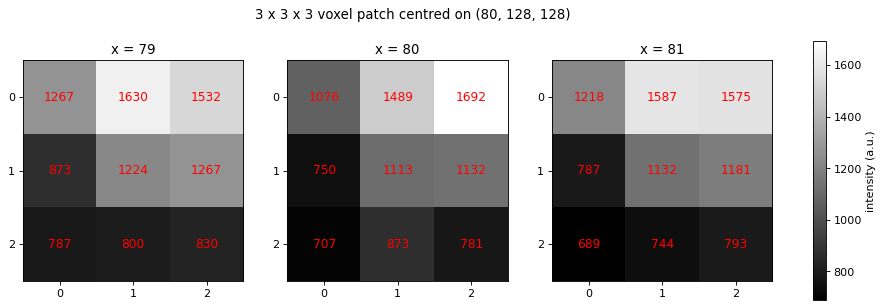

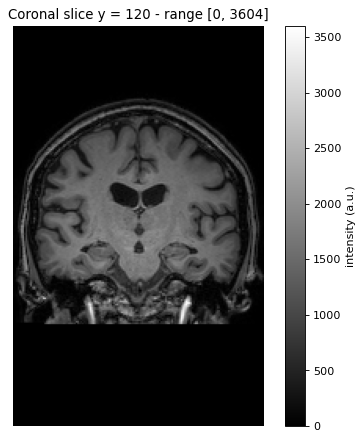

whole volume: [0, 4785], 99.9th percentile of non-zero voxels = 2097


brightest voxel at (np.int64(106), np.int64(126), np.int64(86))


In [11]:
# ANSWER: 1. a 3 x 3 x 3 voxel patch in the brain and one in the background
c = (80, 128, 128)                                    # centre of the volume
patch = data[c[0]-1:c[0]+2, c[1]-1:c[1]+2, c[2]-1:c[2]+2]
patch_bg = data[0:3, 0:3, 0:3]
np.set_printoptions(suppress=True)
print("3x3x3 patch around voxel", c, "(one 3x3 block per x index):\n", patch)
print("\nbackground patch data[0:3, 0:3, 0:3]:\n", patch_bg)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for k in range(3):
    im = axes[k].imshow(patch[k], cmap="gray", vmin=patch.min(), vmax=patch.max())
    axes[k].set_title(f"x = {c[0]-1+k}"); axes[k].set_xticks(range(3)); axes[k].set_yticks(range(3))
    for (i, j), v in np.ndenumerate(patch[k]):
        axes[k].text(j, i, f"{v:.0f}", ha="center", va="center", color="red", fontsize=11)
fig.colorbar(im, ax=axes.tolist(), fraction=0.02, label="intensity (a.u.)")
plt.suptitle(f"3 x 3 x 3 voxel patch centred on {c}"); plt.show()

# 3. one slice with its colour bar
sl = data[:, 120, :]
plt.figure(figsize=(7, 6.5))
plt.imshow(ndimage.rotate(sl, 90, order=0), cmap="gray"); plt.colorbar(label="intensity (a.u.)")
plt.title(f"Coronal slice y = 120 - range [{sl.min():.0f}, {sl.max():.0f}]"); plt.axis("off"); plt.show()
print(f"whole volume: [{data.min():.0f}, {data.max():.0f}], 99.9th percentile of non-zero voxels = {np.percentile(data[data > 0], 99.9):.0f}")
print("brightest voxel at", np.unravel_index(data.argmax(), data.shape))

ANSWER

**1. 3 × 3 × 3 patch.** The patch centred on voxel (80, 128, 128), near the middle of the head, contains values from 689 to 1692. Within 3 mm the intensity changes by more than a factor of 2, which shows that the patch lies at a tissue boundary: values around 1500–1700 correspond to white matter, and values around 700–900 to grey matter or partial-volume voxels mixing tissue and CSF. A background patch (`data[0:3, 0:3, 0:3]`) contains only zeros (air outside the head).

**2. Do these numbers convey direct information? On what does the range depend?**
- Not by themselves. MRI intensities are in **arbitrary units**: they are relative signal amplitudes, not a physical quantity calibrated like Hounsfield units in CT. A value of 1500 has no meaning on its own; only the **contrast between tissues within the same image** is meaningful. In this T1-weighted image: white matter (~1500–1600) > grey matter (~1100–1200) > CSF (~300).
- The intensity range depends on:
  - the tissue properties: proton density and relaxation times T1, T2, T2*;
  - the sequence and its parameters (T1-weighted here: TR, TE, TI, flip angle);
  - the field strength;
  - the receiver coil sensitivity and gain, whose spatial variation (**bias field**) makes the same tissue brighter near the coils;
  - the scanner's reconstruction scaling and any post-processing (interpolation, bias correction, normalisation, conversion to float32);
  - the patient.
- The range (here 0–4785) therefore differs between scanners, sessions and subjects. Intensity normalisation is needed before images are compared or used to train a model.

**3. Slice with colour bar.** The coronal slice y = 120 ranges over [0, 3604]. Most brain tissue lies below ~2000, and the upper half of the colour scale is used by only a few very bright voxels: tubular structures at the skull base, most likely blood vessels. The whole volume reaches 4785 (voxel (106, 126, 86), near the skull base), while 99.9 % of the non-zero voxels are below 2097. This handful of outliers sets the range of the colour bar and compresses the contrast of the brain tissues, which motivates the normalisation and windowing methods below.

As seen in the last lab there a few ways to handle the range of intensities so as to display it as an image. By default matplotlib normalizes them  when you use the `imshow` function. 
For a particular slice try the following

**METHOD 1**: Min-Max Normalization

Do the min-max normalization for the whole image and visualize one slice. Also plot the colorbar and comment on what you observe

volume: [0, 4785] -> [0.00, 1.00]
slice y = 120: [0.000, 0.753]


percentiles 50/95/99.9 of the non-zero voxels after normalisation: [0.141 0.343 0.438]


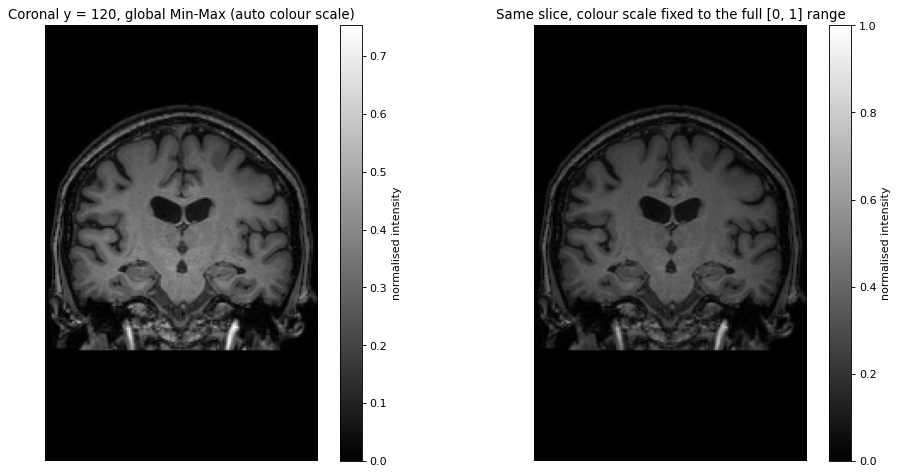

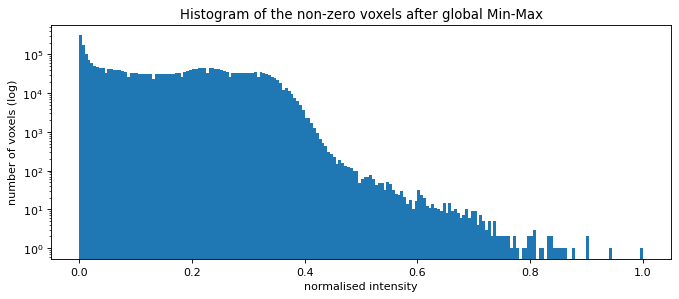

np.allclose(data_mm[:, 120, :], slice1_original.npy): True


In [12]:
#CODE
# ANSWER: METHOD 1 - Min-Max normalisation of the whole 3D volume to [0, 1]
d_min, d_max = data.min(), data.max()
data_mm = (data - d_min) / (d_max - d_min)
sl_y = 120
sl_mm = ndimage.rotate(data_mm[:, sl_y, :], 90, order=0)
print(f"volume: [{d_min:.0f}, {d_max:.0f}] -> [{data_mm.min():.2f}, {data_mm.max():.2f}]")
print(f"slice y = {sl_y}: [{sl_mm.min():.3f}, {sl_mm.max():.3f}]")
print("percentiles 50/95/99.9 of the non-zero voxels after normalisation:",
      np.round(np.percentile(data_mm[data > 0], [50, 95, 99.9]), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im = axes[0].imshow(sl_mm, cmap="gray"); axes[0].axis("off")
axes[0].set_title(f"Coronal y = {sl_y}, global Min-Max (auto colour scale)")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="normalised intensity")
im = axes[1].imshow(sl_mm, cmap="gray", vmin=0, vmax=1); axes[1].axis("off")
axes[1].set_title("Same slice, colour scale fixed to the full [0, 1] range")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label="normalised intensity")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 3.8))
plt.hist(data_mm[data > 0], bins=200, range=(0, 1), color="tab:blue")
plt.yscale("log"); plt.xlabel("normalised intensity"); plt.ylabel("number of voxels (log)")
plt.title("Histogram of the non-zero voxels after global Min-Max"); plt.show()
print("np.allclose(data_mm[:, 120, :], slice1_original.npy):", np.allclose(data_mm[:, 120, :], np.load("slice1_original.npy")))

Comment

**ANSWER (comment)**
- **Mapping:** the global Min-Max maps the whole volume from [0, 4785] to [0, 1]. On the coronal slice y = 120, the values only reach **0.753**, not 1, because the brightest voxel of the volume lies in another slice. A slice normalised with the volume's min and max does not necessarily span the full range. This normalised slice is exactly `slice1_original.npy`, used in Part 2 (`np.allclose` returns `True`).
- **Colour bar:** with automatic scaling, matplotlib stretches [0, 0.753] over the colour map and the image looks the same as before; only the labels change. With a fixed [0, 1] colour scale, the image is visibly darker.
- **The range is poorly used:** the median non-zero voxel is at 0.141, the 95th percentile at 0.343 and the 99.9th percentile at 0.438. More than half of the output range ([0.44, 1]) is used by fewer than 0.1 % of the voxels (the bright vessels). The brain tissues are compressed into less than half of the grey levels, so the GM/WM contrast is low. The log histogram shows the long, sparse tail above 0.45.
- **Pros and cons:** Min-Max is linear, so it keeps the relative intensities. Applied globally, it puts all slices on the same scale, so slices remain comparable (unlike a per-slice normalisation). But it is **very sensitive to outliers**. Robust alternatives are a percentile-based Min-Max (e.g. 0.5th–99.5th percentiles) or windowing (next section).

**METHOD 2**: Windowing

Get the max and min intensities of the whole 3D image. Select a window center and width of your choice and apply the method to a slice of the image and visualize it (plot the colorbar too)

The main observation is that we can use windowing method to highlight some intensities of choice if it is priorly known what some structures might look like in the scans.

You can plot the profile to compare the actual slice and the same slice after windowing. Comment on the graph of their intensities

min and max of the whole 3D image: 0, 4785
percentiles 5/25/50/75/95/99.9 of the non-zero voxels: [  12.  154.  677. 1187. 1642. 2097.]


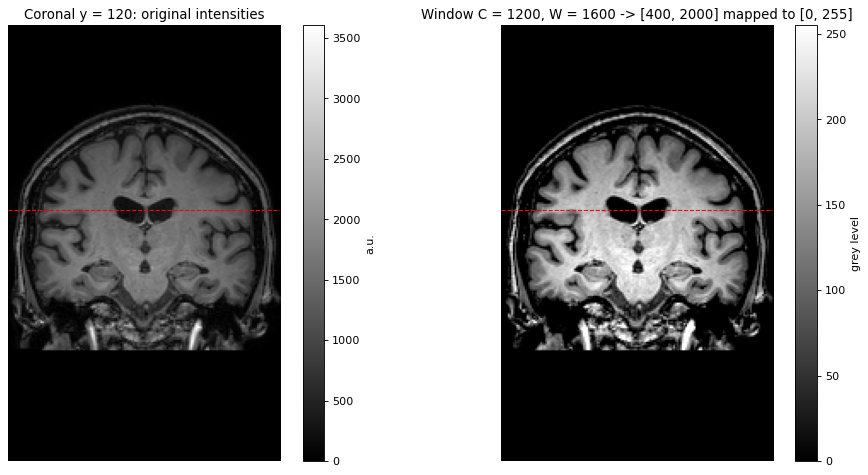

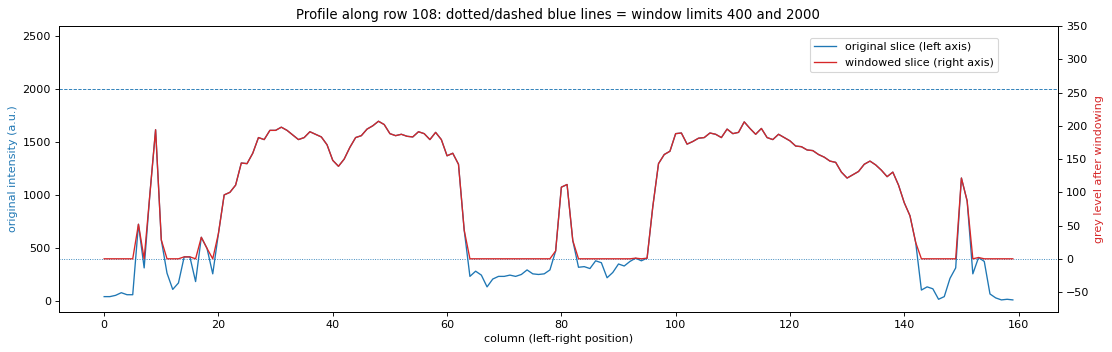

non-zero voxels of this slice clipped by the window: below 29.1%, above 0.6%
profile row 108: 32% of the points set to 0, 0% set to 255


In [13]:
#CODE
# ANSWER: METHOD 2 - windowing of the NIfTI volume
v_min, v_max = data.min(), data.max()
print(f"min and max of the whole 3D image: {v_min:.0f}, {v_max:.0f}")
nz = data[data > 0]
print("percentiles 5/25/50/75/95/99.9 of the non-zero voxels:", np.round(np.percentile(nz, [5, 25, 50, 75, 95, 99.9])))

def apply_window(x, center, width, out_max=255.0):
    """Clip to [center - width/2, center + width/2] then Min-Max to [0, out_max]."""
    lo, hi = center - width / 2, center + width / 2
    return (np.clip(x, lo, hi) - lo) / (hi - lo) * out_max

# window chosen to cover the brain tissues (CSF ~300, grey matter ~1100-1200, white matter ~1600)
WC1, WW1 = 1200, 1600                     # -> [400, 2000]
sl_raw = ndimage.rotate(data[:, sl_y, :], 90, order=0)
sl_win = apply_window(sl_raw, WC1, WW1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im = axes[0].imshow(sl_raw, cmap="gray"); axes[0].axis("off")
axes[0].set_title(f"Coronal y = {sl_y}: original intensities"); fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="a.u.")
im = axes[1].imshow(sl_win, cmap="gray", vmin=0, vmax=255); axes[1].axis("off")
axes[1].set_title(f"Window C = {WC1}, W = {WW1} -> [{WC1-WW1//2}, {WC1+WW1//2}] mapped to [0, 255]")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label="grey level")
row = 108                                  # row through the lateral ventricles
for a in axes: a.axhline(row, color="r", ls="--", lw=1)
plt.tight_layout(); plt.show()

# intensity profiles along the red line
fig, ax1 = plt.subplots(figsize=(14, 4.5))
ax1.plot(sl_raw[row], color="tab:blue", lw=1.2, label="original slice (left axis)")
# axes aligned so that the window limits [lo, hi] of the left axis coincide with 0 and 255 of the right axis
lo_w, hi_w = WC1 - WW1 / 2, WC1 + WW1 / 2
y0, y1 = -100, max(2600, sl_raw[row].max() * 1.05)
ax1.set_ylim(y0, y1)
for lv, ls_ in [(WC1 - WW1 / 2, ":"), (WC1 + WW1 / 2, "--")]:
    ax1.axhline(lv, color="tab:blue", ls=ls_, lw=0.8)
ax1.set_xlabel("column (left-right position)"); ax1.set_ylabel("original intensity (a.u.)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(sl_win[row], color="tab:red", lw=1.2, label="windowed slice (right axis)")
ax2.set_ylabel("grey level after windowing", color="tab:red")
ax2.set_ylim((y0 - lo_w) / WW1 * 255, (y1 - lo_w) / WW1 * 255)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.title(f"Profile along row {row}: dotted/dashed blue lines = window limits {WC1-WW1//2} and {WC1+WW1//2}")
plt.tight_layout(); plt.show()
print(f"non-zero voxels of this slice clipped by the window: below {np.mean(sl_raw[sl_raw > 0] < WC1 - WW1/2):.1%},"
      f" above {np.mean(sl_raw[sl_raw > 0] > WC1 + WW1/2):.1%}")
print(f"profile row {row}: {np.mean(sl_raw[row] < WC1 - WW1/2):.0%} of the points set to 0, {np.mean(sl_raw[row] > WC1 + WW1/2):.0%} set to 255")

Comment

**ANSWER (comment)**
- **Choice of the window:** the whole volume ranges over [0, 4785]. From the percentiles and the tissue values found above (CSF ~300, GM ~1100–1200, WM ~1600), the window was set to **C = 1200, W = 1600, i.e. [400, 2000]**. It covers grey and white matter and excludes:
  - the darkest values (CSF, bone, air, noise: 29 % of the non-zero voxels of this slice are below 400), which are set to 0;
  - the bright outliers above 2000 (0.6 % of the non-zero voxels: vessels and fat), which are set to 255.
- **Image:** the contrast between grey and white matter is much stronger than with Min-Max: the cortical ribbon, the deep grey nuclei and the white matter are clearly separated. Ventricles and sulci become uniformly black, and the vessels at the skull base saturate to white.
- **Profiles** (row 108, crossing both lateral ventricles; the axes are aligned so that 400 and 2000 on the left correspond to 0 and 255 on the right):
  - between 400 and 2000 the windowed profile **exactly superimposes** the original one, because windowing is linear inside the window;
  - the slope is 255/1600 ≈ 0.16 grey level per unit, against 255/4785 ≈ 0.053 for the global Min-Max, so the contrast inside the window is amplified about **3×**;
  - outside the window the profile is **flat**: 32 % of the points on this row (ventricles, CSF, scalp and air) are clipped to 0, and their internal variations (e.g. 150–300 inside the ventricles) are lost; no point on this row exceeds 2000.
- **Trade-off:** windowing gives more contrast for the intensities of interest, at the cost of discarding everything outside the window. It must therefore be chosen with prior knowledge of the intensities of the structures to highlight.

**Further exploration**: Try the same for a different window center and width (either with the same view or you can change it - your choice). Comment on if you observe any changes

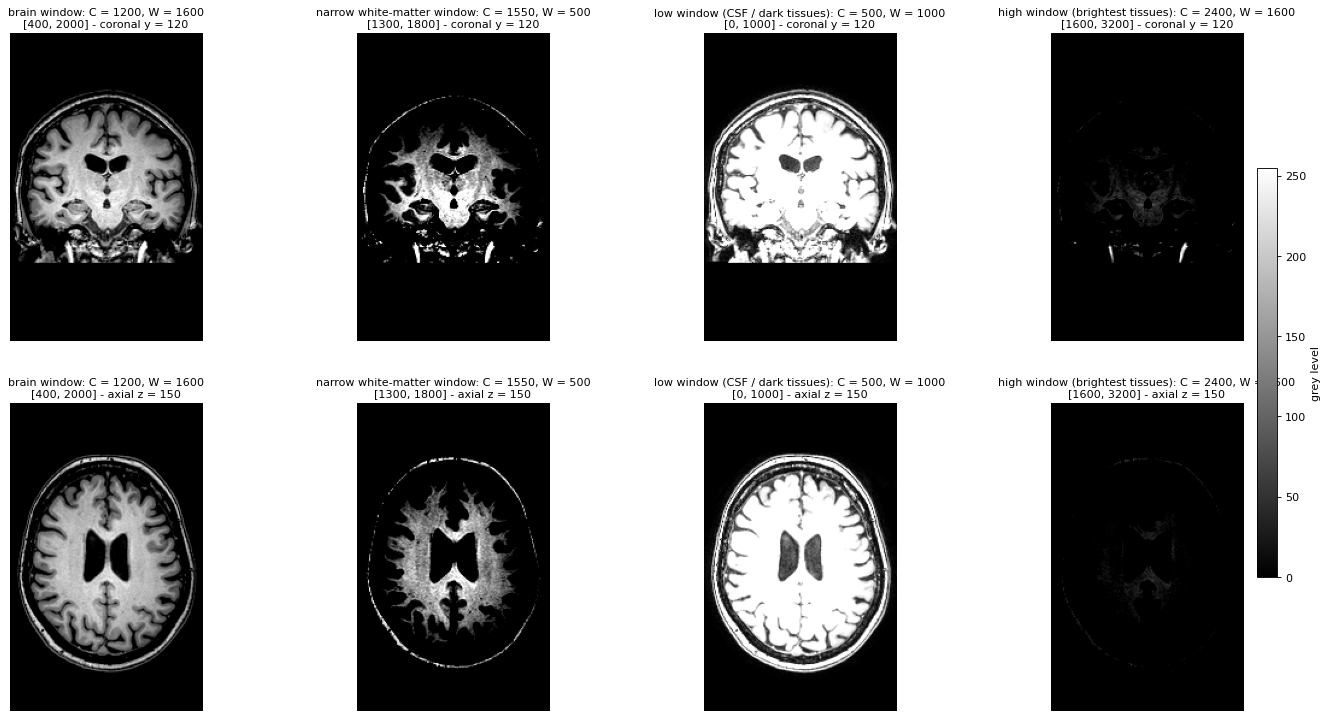

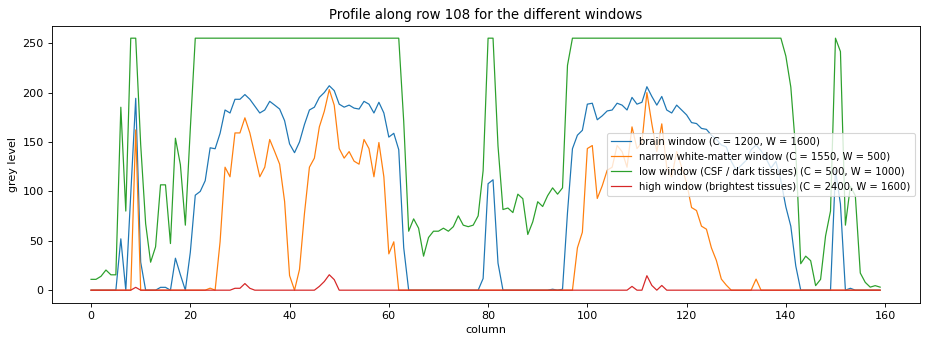

In [14]:
#CODE
# ANSWER: two other windows on the same slice and on an axial slice
windows = [(WC1, WW1, "brain window"),
           (1550, 500, "narrow white-matter window"),
           (500, 1000, "low window (CSF / dark tissues)"),
           (2400, 1600, "high window (brightest tissues)")]
sl_ax = ndimage.rotate(data[:, :, 150], 90, order=0)
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for k, (c_, w_, name) in enumerate(windows):
    for r, (s_, lab) in enumerate([(sl_raw, f"coronal y = {sl_y}"), (sl_ax, "axial z = 150")]):
        im = axes[r, k].imshow(apply_window(s_, c_, w_), cmap="gray", vmin=0, vmax=255)
        axes[r, k].set_title(f"{name}: C = {c_}, W = {w_}\n[{c_-w_//2}, {c_+w_//2}] - {lab}", fontsize=10)
        axes[r, k].axis("off")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.015, pad=0.01, label="grey level")
plt.show()

fig, ax = plt.subplots(figsize=(14, 4.5))
for c_, w_, name in windows:
    ax.plot(apply_window(sl_raw[row], c_, w_), lw=1.1, label=f"{name} (C = {c_}, W = {w_})")
ax.set_xlabel("column"); ax.set_ylabel("grey level"); ax.legend(fontsize=9)
ax.set_title(f"Profile along row {row} for the different windows"); plt.show()

Comment

**ANSWER (comment)** Four windows were applied to the same coronal slice and to an axial slice (z = 150):
- **Brain window, C = 1200, W = 1600 [400, 2000]:** balanced view of grey and white matter (reference).
- **Narrow white-matter window, C = 1550, W = 500 [1300, 1800]:** very high contrast *inside* the white matter, which shows subtle intensity variations within it (partly the bias field). Grey matter and CSF are all black, so the GM/WM boundary is very sharp. This would help to inspect white-matter lesions or to check a WM segmentation.
- **Low window, C = 500, W = 1000 [0, 1000]:** white matter and most grey matter are saturated to white, while the dark structures become visible: ventricles, CSF in the sulci, and the layers of skull and scalp. The outline of the brain against the CSF is very clear.
- **High window, C = 2400, W = 1600 [1600, 3200]:** almost all the brain is black. Only the brightest structures remain: vessels at the skull base, parts of the scalp and fat, and the brightest white-matter voxels.

The profiles show the same effect: each window maps a different intensity interval linearly onto [0, 255] and flattens everything else. **The image data are identical; only the window changes what is visible.** Windowing is therefore a visualisation tool that can highlight particular tissues, provided their intensity range is known (histogram, prior knowledge). MRI intensities are not standardised, so these windows are specific to this scan and would have to be adapted for another acquisition. CT is different: fixed presets in Hounsfield units (brain, bone, lung) can be reused across patients.

### Display multiple slices

This is a simple python code exercise. 

Write a code to display any 3 consecutive slices (closer to the center) from the 3 views as a grid using `matplotlib` and use `subplots` to display the slices in a grid with the colorbar. (You can use either Method 1 or 2 for the normalization)

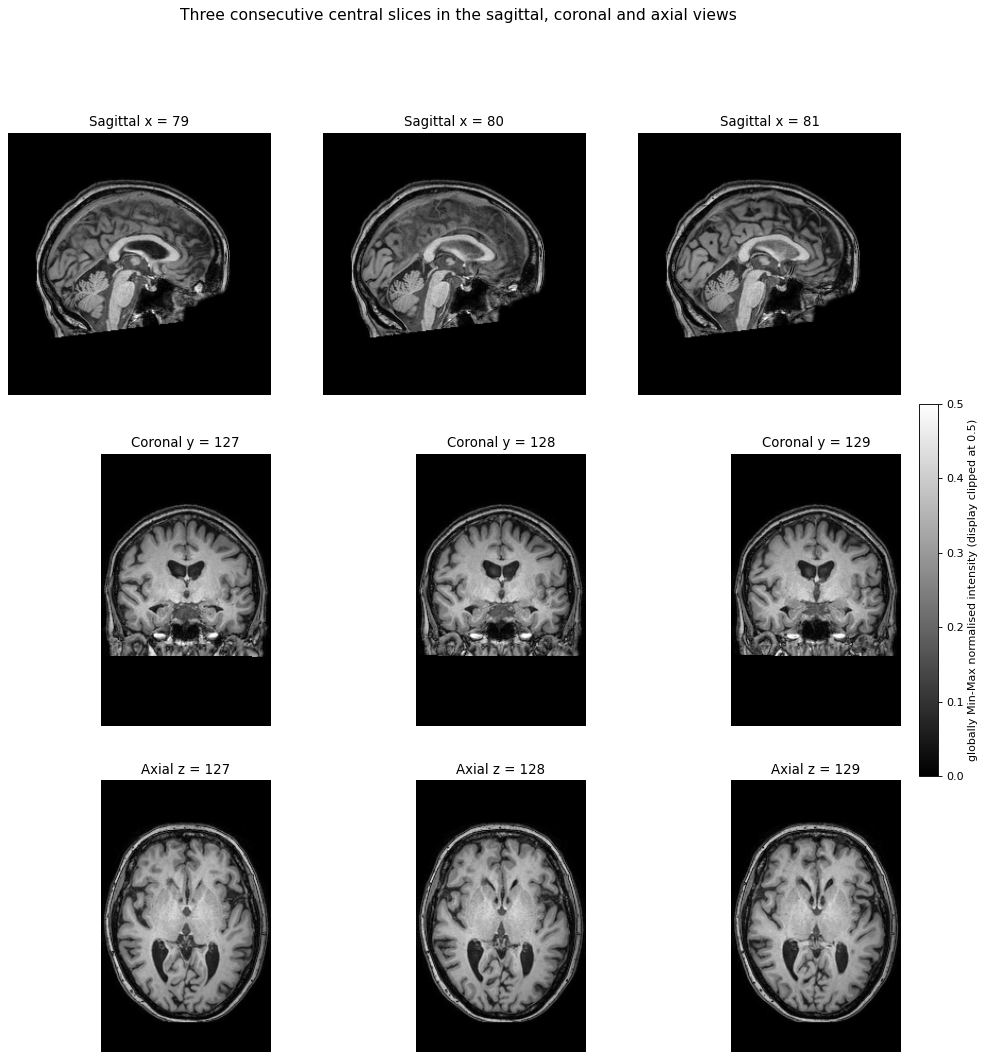

In [15]:
# CODE
# ANSWER: 3 consecutive slices close to the centre, for the 3 views (global Min-Max normalisation, METHOD 1)
centre = np.array(data.shape) // 2                        # (80, 128, 128)
offsets = [-1, 0, 1]
getters = [("Sagittal x", lambda i: data_mm[i, :, :]),
           ("Coronal y", lambda i: data_mm[:, i, :]),
           ("Axial z", lambda i: data_mm[:, :, i])]
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for r, (name, get) in enumerate(getters):
    for k, o in enumerate(offsets):
        i = centre[r] + o
        im = axes[r, k].imshow(ndimage.rotate(get(i), 90, order=0), cmap="gray", vmin=0, vmax=0.5)
        axes[r, k].set_title(f"{name} = {i}"); axes[r, k].axis("off")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02,
             label="globally Min-Max normalised intensity (display clipped at 0.5)")
fig.suptitle("Three consecutive central slices in the sagittal, coronal and axial views", fontsize=14)
plt.show()

**ANSWER (comment)**
- **Layout:** the grid shows three consecutive central slices (index centre − 1, centre, centre + 1) for each view:
  - sagittal x = 79–81: near the mid-sagittal plane, with corpus callosum, brainstem, cerebellum and lateral ventricle;
  - coronal y = 127–129: through the lateral ventricles and the temporal lobes, with bright vessels at the skull base;
  - axial z = 127–129: at the level of the lateral ventricles and the deep grey nuclei.
- **Consecutive slices:** they are only 1 mm apart and look almost identical. Only small changes in the shape of the ventricles and sulci appear, which illustrates the high through-plane resolution and spatial continuity of an isotropic 3D acquisition.
- **Common scale:** all nine panels use the same global Min-Max normalisation (Method 1) and the same colour scale, with one shared colour bar, so intensities are directly comparable between views and slices. The display is clipped at 0.5 (just above the 99.9th percentile, 0.44) so that the bright outliers do not darken the brain.

## Other References

1. Nilearn: is another library that has more functions for plotting and ML tools (using scikit-learn) to work with biomedical images (https://nilearn.github.io/stable/index.html)
2. https://neuraldatascience.io/8-mri/read_viz.html (Some notes for both DICOM and NIfTI)
3. Some basic idea of MRI: https://www.weizmann.ac.il/chembiophys/assaf_tal/sites/chemphys.assaf_tal/files/uploads/MRI2021/Lecture%202%20-%20MRI%20As%20a%20Black%20Box.pdf
4. https://imagej.net/software/fiji/downloads#installation Is a tool you can use to view the image

### **Part 2 : Segmentation of an MRI image**

This part is done on the one slice of the available compressed .nii file save to a .npy file

### I. Manual Segmentation
/!\ The points don't rely on the quality of the segmentation, but on your answers to the questions.
This exercise is here to present you different ways to isolate the brain on MRI images. Some useful links are given but you are expected to do your own reasearches on the concepts as the quality of the implementation is not taken into account.

Some comments are available to guide you.

Tasks : 
- Load the necessary library and use "slice1_original.npy" as the image you would like to segment
- Try doing a histogram of the pixel intensities in the image 
- Identify different thresholds values and using 'cv2.threshold', generate binary masks and plot those masks (HINT : https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)
- **BONUS**: For better results, you can use morphological operations, like erode, dilate, etc. (cf. https://docs.opencv.org/3.4/db/df6/tutorial_erosion_dilatation.html & for theoretical details : https://fr.wikipedia.org/wiki/Morphologie_math%C3%A9matique ) 

0.0 0.7531870428422153
shape: (160, 256) dtype: float64


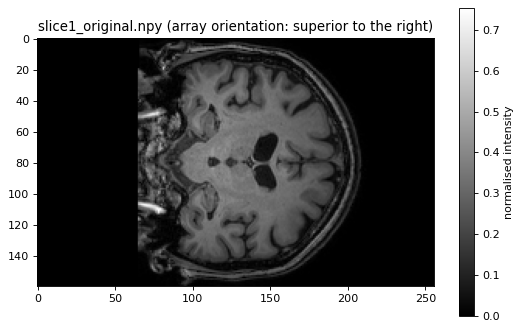

In [16]:
import cv2
import cv2
import numpy as np
import matplotlib.pyplot as plt


# ANSWER: path completed
slice_1 = np.load(r"slice1_original.npy")
print(slice_1.min(), slice_1.max())
print("shape:", slice_1.shape, "dtype:", slice_1.dtype)
# ANSWER: this slice is the coronal slice y = 120 of the NIfTI volume, globally Min-Max normalised
# (array orientation: rows = left-right axis, columns = inferior -> superior)
plt.figure(figsize=(8, 5)); plt.imshow(slice_1, cmap="gray"); plt.colorbar(label="normalised intensity")
plt.title("slice1_original.npy (array orientation: superior to the right)"); plt.show()

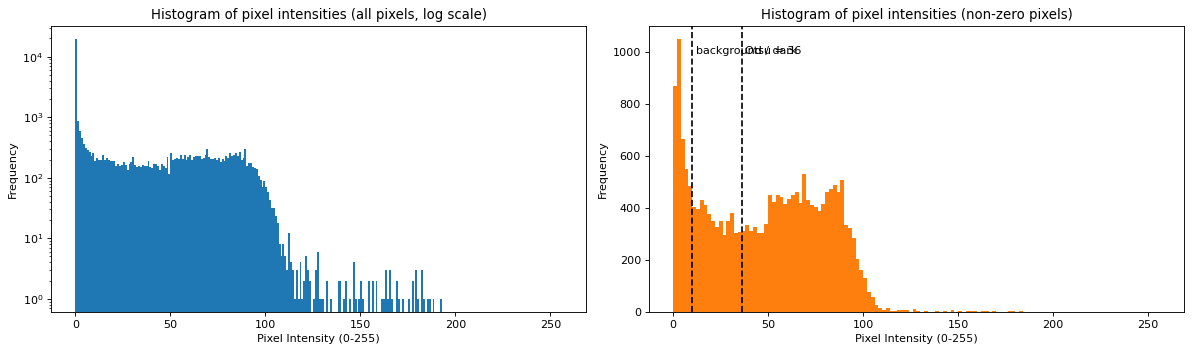

fraction of zero pixels: 48.5 % | max: 192 | Otsu threshold: 36.0


In [17]:
#code to fill by the student (ravel of the slice and histogram of the pixel intensities)

#plt.figure()
#plt.hist( ? , bins= ? , range= ? )
#plt.title('Histogram of pixel intensities')
#plt.xlabel('Pixel Intensity')
#plt.ylabel('Frequency')
#plt.show()

# ANSWER: work on an 8-bit version (cv2 thresholding/Otsu expect uint8), same scale as the .npy x 255
slice_u8 = np.round(slice_1 * 255).astype(np.uint8)
pixels = slice_u8.ravel()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(pixels, bins=256, range=(0, 256))
axes[0].set_yscale("log"); axes[0].set_title("Histogram of pixel intensities (all pixels, log scale)")
axes[1].hist(pixels[pixels > 0], bins=128, range=(0, 256), color="tab:orange")
axes[1].set_title("Histogram of pixel intensities (non-zero pixels)")
for a in axes:
    a.set_xlabel("Pixel Intensity (0-255)"); a.set_ylabel("Frequency")
otsu_t, _ = cv2.threshold(slice_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
for t, lab in [(10, "background / dark"), (otsu_t, f"Otsu = {otsu_t:.0f}")]:
    axes[1].axvline(t, color="k", ls="--"); axes[1].text(t + 2, axes[1].get_ylim()[1] * 0.9, lab)
plt.tight_layout(); plt.show()
print("fraction of zero pixels: %.1f %%" % (100 * np.mean(pixels == 0)), "| max:", pixels.max(), "| Otsu threshold:", otsu_t)

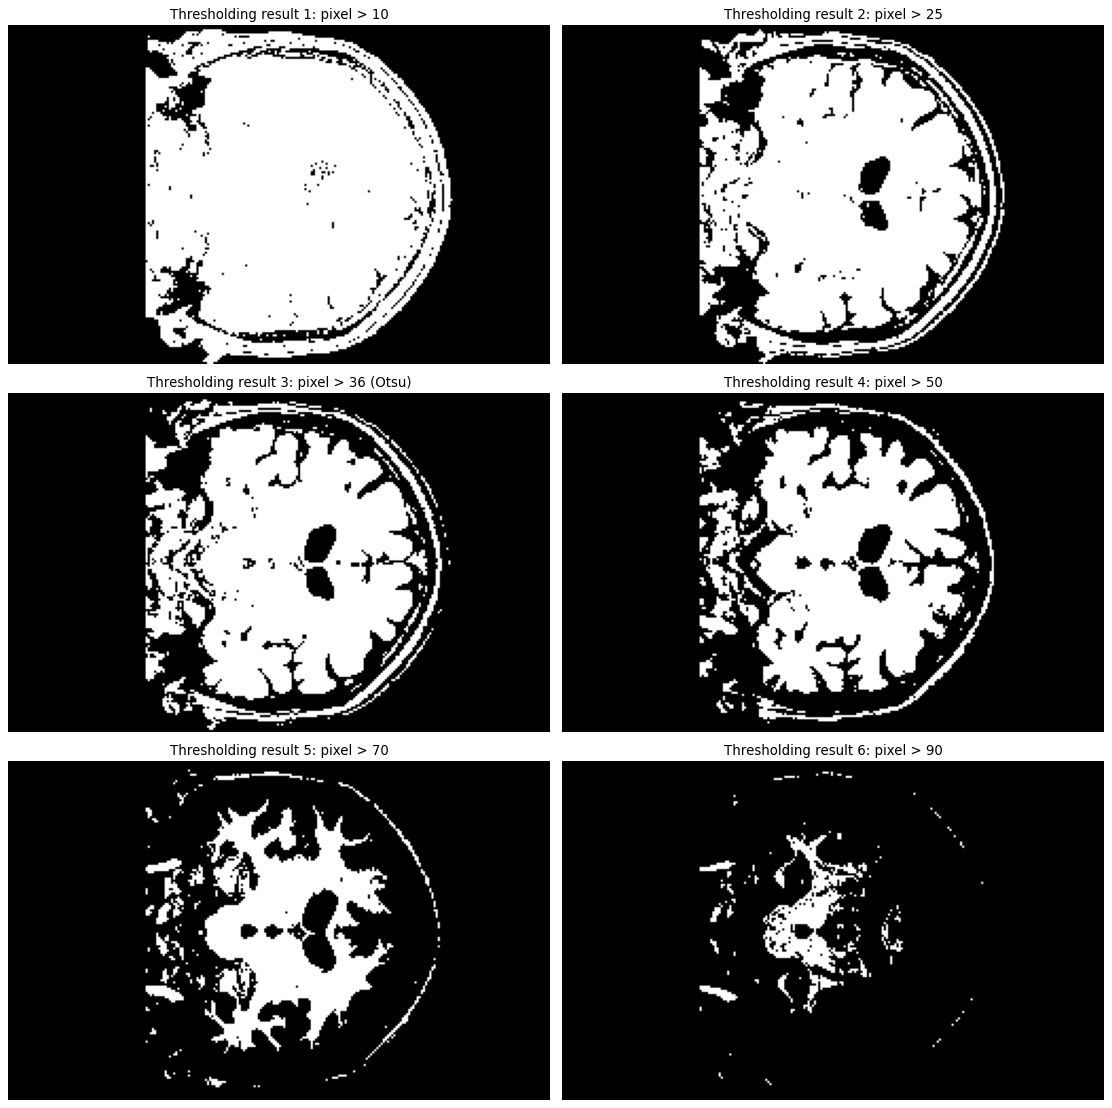

In [18]:
#ret1, thresh1 = cv2.threshold(#image, #min_thresh, #maxthresh, cv2.THRESH_BINARY) ... etc (test other values and plot all of them)
# if you have 6 thresholds to test, you can use a subplot with 3 lines and 2 columns


#plt.subplot(3, 2, 1)
#plt.imshow(thresh1, cmap='gray')
#plt.title('Thresholding result 1')
#plt.subplot(3, 2, 2)
#plt.imshow(thresh2, cmap='gray')
#plt.title('Thresholding result 2')
#plt.subplot(3, 2, 3)
#plt.imshow(thresh3, cmap='gray')
#plt.title('Thresholding result 3')
#plt.subplot(3, 2, 4)
#plt.imshow(thresh4, cmap='gray')
#plt.title('Thresholding result 4')
#plt.subplot(3, 2, 5)
#plt.imshow(thresh5, cmap='gray')
#plt.title('Thresholding result 5')
#plt.subplot(3, 2, 6)
#plt.imshow(thresh6, cmap='gray')
#plt.tight_layout()
#plt.show()

# ANSWER: six thresholds chosen from the histogram (0-255 scale)
ret1, thresh1 = cv2.threshold(slice_u8, 10, 255, cv2.THRESH_BINARY)       # head vs air
ret2, thresh2 = cv2.threshold(slice_u8, 25, 255, cv2.THRESH_BINARY)
ret3, thresh3 = cv2.threshold(slice_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # automatic (Otsu)
ret4, thresh4 = cv2.threshold(slice_u8, 50, 255, cv2.THRESH_BINARY)
ret5, thresh5 = cv2.threshold(slice_u8, 70, 255, cv2.THRESH_BINARY)       # mostly white matter
ret6, thresh6 = cv2.threshold(slice_u8, 90, 255, cv2.THRESH_BINARY)
results_t = [(ret1, thresh1), (ret2, thresh2), (ret3, thresh3), (ret4, thresh4), (ret5, thresh5), (ret6, thresh6)]
plt.figure(figsize=(14, 14))
for k, (r_, t_) in enumerate(results_t):
    plt.subplot(3, 2, k + 1)
    plt.imshow(t_, cmap='gray')
    plt.title(f"Thresholding result {k + 1}: pixel > {r_:.0f}" + (" (Otsu)" if k == 2 else ""))
    plt.axis("off")
plt.tight_layout()
plt.show()

8 connected components after erosion; the largest one (4074 px) is kept


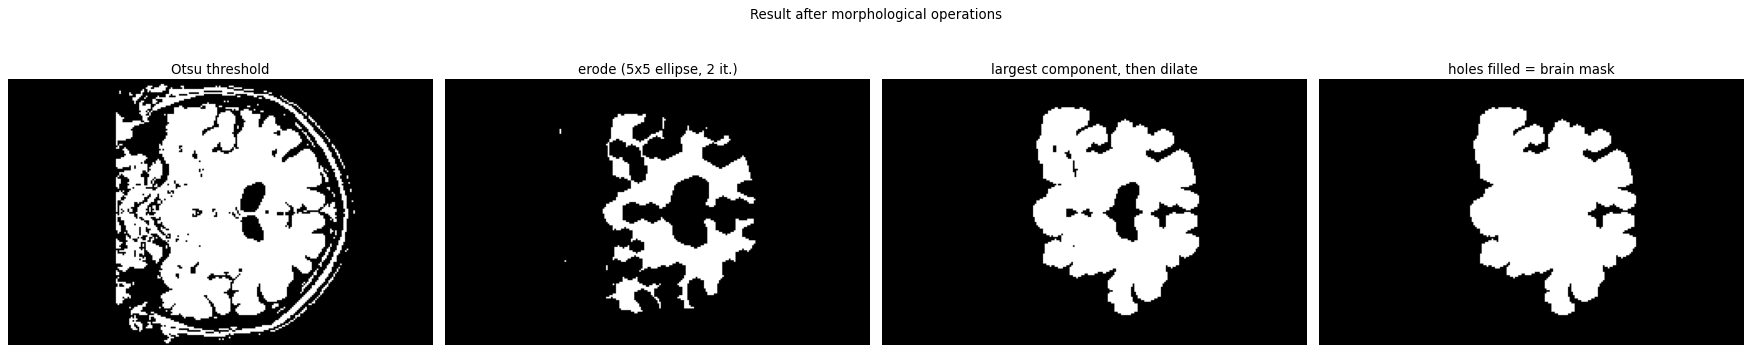

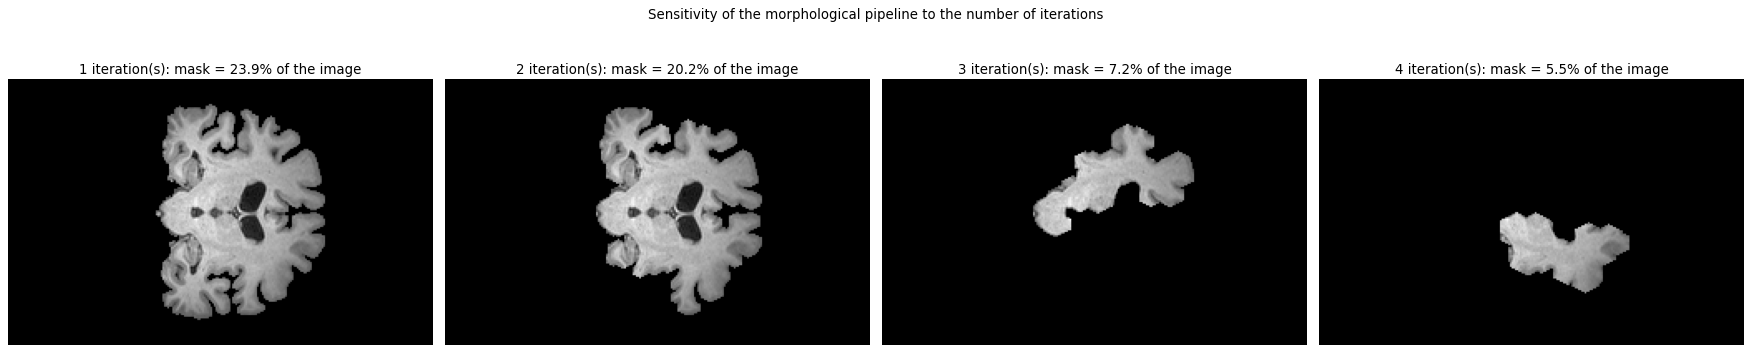

In [19]:
# BONUS CODE
# kernel =
# erode =  cv2.erode(thresh , kernel, iterations= ?)
# dilate = cv2.dilate(erode, kernel, iterations= ?)
#plot du résultat

#plot du résultat
#plt.figure()
#plt.imshow(erode, cmap='gray')
#plt.title('Result after morphological operations : erode')
#plt.colorbar()
#plt.show()


# dilate = cv2.dilate(erode, kernel, iterations= ?)
#plot du résultat
#plt.figure()
#plt.imshow(dilate, cmap='gray')
#plt.title('Result after morphological operations :erode then dilate')
#plt.colorbar()
#plt.show()

# ANSWER (BONUS): erode -> keep the largest connected component -> dilate -> fill holes
from scipy import ndimage
thresh = thresh3                                            # Otsu mask
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
n_it = 2
erode = cv2.erode(thresh, kernel, iterations=n_it)          # breaks the thin links brain <-> skull/scalp
n_lab, labels, stats, _ = cv2.connectedComponentsWithStats(erode, connectivity=8)
largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])        # label 0 is the background
brain_core = np.where(labels == largest, 255, 0).astype(np.uint8)
dilate = cv2.dilate(brain_core, kernel, iterations=n_it)    # restores the size of the kept component
brain_mask = ndimage.binary_fill_holes(dilate > 0).astype(np.uint8) * 255   # ventricles / sulci holes filled
print(f"{n_lab - 1} connected components after erosion; the largest one ({stats[largest, cv2.CC_STAT_AREA]} px) is kept")

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for a, (im_, t_) in zip(axes, [(thresh, "Otsu threshold"), (erode, f"erode (5x5 ellipse, {n_it} it.)"),
                               (dilate, "largest component, then dilate"), (brain_mask, "holes filled = brain mask")]):
    a.imshow(im_, cmap='gray'); a.set_title(t_); a.axis("off")
plt.suptitle("Result after morphological operations"); plt.tight_layout(); plt.show()

# sensitivity to the number of iterations
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for a, it in zip(axes, [1, 2, 3, 4]):
    e_ = cv2.erode(thresh, kernel, iterations=it)
    n_, l_, s_, _ = cv2.connectedComponentsWithStats(e_, connectivity=8)
    m_ = ndimage.binary_fill_holes(cv2.dilate(np.where(l_ == 1 + np.argmax(s_[1:, cv2.CC_STAT_AREA]), 255, 0).astype(np.uint8),
                                              kernel, iterations=it) > 0)
    a.imshow(np.where(m_, slice_1, 0), cmap="gray"); a.set_title(f"{it} iteration(s): mask = {m_.mean():.1%} of the image"); a.axis("off")
plt.suptitle("Sensitivity of the morphological pipeline to the number of iterations"); plt.tight_layout(); plt.show()

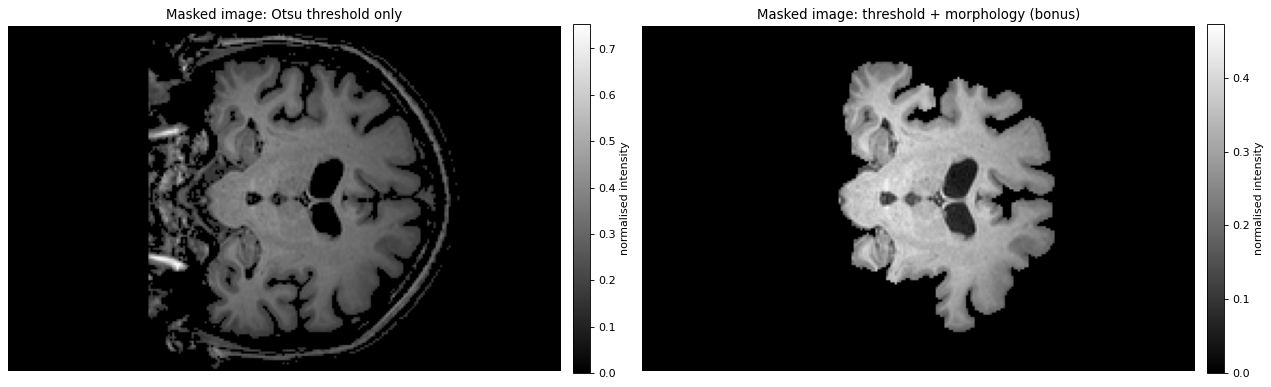

In [20]:
#Apply binary mask and plot the results


#plt.figure()
#plt.imshow(masked_image, cmap='gray')
#plt.title('Masked image')
#plt.colorbar()
#plt.show()

# ANSWER
masked_image = np.where(brain_mask > 0, slice_1, 0)
masked_thresh_only = np.where(thresh3 > 0, slice_1, 0)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for a, (im_, t_) in zip(axes, [(masked_thresh_only, "Masked image: Otsu threshold only"),
                               (masked_image, "Masked image: threshold + morphology (bonus)")]):
    h_ = a.imshow(im_, cmap='gray'); a.set_title(t_); a.axis("off")
    fig.colorbar(h_, ax=a, fraction=0.03, pad=0.02, label="normalised intensity")
plt.tight_layout(); plt.show()

/!\ Don't spend too much time on threshold, eroding and dilating as this method of segmentation shouldn't work very well

Questions:
1) Would these functions and operations work well for MRI? Why not? Why do they not work well for MRI images?
2) Would it work on CT images? Why ?


ANSWERS : 

1. **ANSWER – Would thresholding and morphology work well for MRI? No, not on their own.**

   **What we observe:**
   - A threshold of 10 separates the head from the air, but keeps the skull, scalp and neck.
   - Thresholds of 25–50 (Otsu = 36) keep the brain together with the scalp, fat and muscles, and the brain stays connected to non-brain tissue in several places.
   - Thresholds of 70–90 keep only white matter and the brightest non-brain structures (fat, vessels) and lose the grey matter.
   - **No single threshold isolates the brain.** The morphological pipeline (bonus) gives a reasonable brain mask with 1–2 erosion/dilation iterations, but with 3 iterations it collapses (from 20.2 % to 7.2 % of the image): it is very sensitive to its parameters and specific to this slice.

   **Why MRI is difficult for thresholding:**
   - **Overlapping intensity distributions:** in T1-weighted images, scalp fat and bone marrow are as bright as white matter or brighter, muscle looks like grey matter, and CSF, cortical bone and air are all dark. Intensity alone cannot tell brain from non-brain; spatial and shape information is needed.
   - **No absolute intensity scale:** values are in arbitrary units and vary with the scanner, sequence and subject, so thresholds must be re-tuned for each image.
   - **Intensity inhomogeneity (bias field):** caused by B1 and coil sensitivity, it gives the same tissue different intensities across the image, so a global threshold cannot fit everywhere.
   - **Noise (Rician) and partial-volume effects:** voxels on boundaries mix GM/CSF or tissue/bone, which produces isolated pixels, holes and ragged contours.
   - **Thin connections:** the brain touches meninges, vessels and optic nerves of similar intensity, so the thresholded regions stay connected. The structuring element and the number of iterations needed to cut them depend on the anatomy.
   - **Histogram:** it is not clearly multimodal apart from the background peak. Otsu separates head from background, not brain from non-brain.

   In practice, dedicated methods are used instead: bias-field correction (e.g. N4) followed by skull stripping (BET, atlas registration, deep learning), or region-, model- or learning-based segmentation.

2. **ANSWER – Would it work on CT images? Partly: yes for high-contrast structures, no for soft tissue.**
   - **Where it works:** CT values are calibrated in **Hounsfield units (HU)**, a physical measure of X-ray attenuation (water = 0 HU, air ≈ −1000 HU), which is essentially the same for every scanner and patient. Thresholds therefore have a fixed physical meaning and can be reused (presets). Bone (≈ +300 to > +1000 HU) is very different from soft tissue (≈ +20 to +80 HU) and from air. Thresholding thus segments the skull, other bones, air and lungs, or contrast-filled vessels very reliably, and skull stripping is much easier (threshold the bone, keep the inside). There is no MRI-like bias field.
   - **Where it fails:** CT has **poor soft-tissue contrast**. Grey matter (~35–45 HU) and white matter (~20–30 HU) differ by only 10–15 HU, which is comparable to the image noise. Thresholding therefore cannot separate GM from WM or delineate many soft-tissue lesions. Beam-hardening and metal artefacts and partial-volume effects also disturb thresholds near bone.

### 2. Region based segmentation algorithms

Now let's test the scikit image library 

#### 2.1. Watershed algorithm

Ressources :
- Theory : https://hal.science/hal-00622129/file/lpe.pdf 

- Implementation + Simple Definition : https://scikit-image.org/docs/0.25.x/auto_examples/segmentation/plot_watershed.html

More details : https://www.youtube.com/watch?v=gt5Fibr6uu0 

Tasks :

These tasks steps can be found also here, for Region-Based Segmentation: https://scikit-image.org/docs/0.25.x/auto_examples/applications/plot_coins_segmentation.html , so you will just need to adapt it to your image.

- Using the skimage.filters.sobel, plot the elevation map
- Again, using the histogram of the slice, try to identify the find markers of the background and the brain and create markers for the watershed algorithm 
- Plot the markers map
- Use the watershed transform to fill regions of the elevation maps, starting from the markers identified 

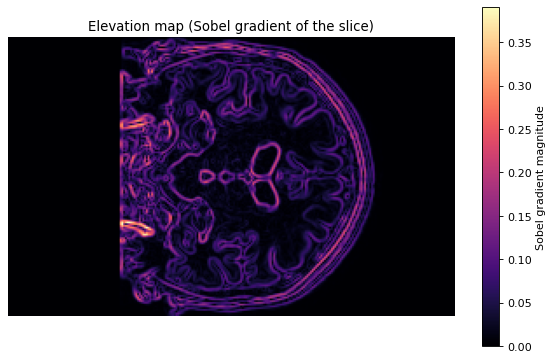

elevation range: [0.000, 0.390]


In [21]:
import skimage as ski

#elevation_map =
# ANSWER
elevation_map = ski.filters.sobel(slice_1)
plt.figure(figsize=(9, 5.5))
plt.imshow(elevation_map, cmap="magma"); plt.colorbar(label="Sobel gradient magnitude")
plt.title("Elevation map (Sobel gradient of the slice)"); plt.axis("off"); plt.show()
print("elevation range: [%.3f, %.3f]" % (elevation_map.min(), elevation_map.max()))

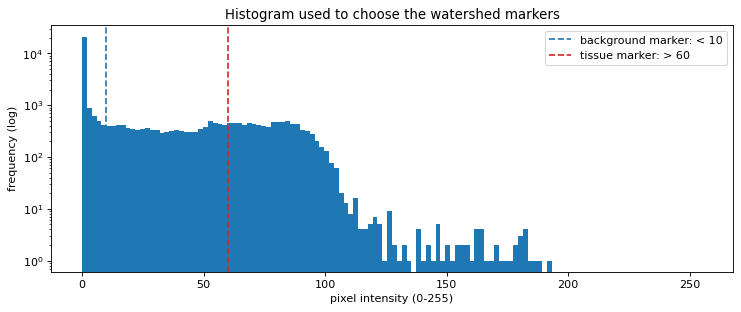

In [22]:
# plot the histogram of the flatten image to identify markers for the watershed algorithm, you can convert 0 to 1 pixel values to 0 to 255 for better visualization
# ANSWER
img_255 = slice_1 * 255
plt.figure(figsize=(11, 4))
plt.hist(img_255.ravel(), bins=128, range=(0, 255))
plt.yscale("log")
plt.axvline(10, color="tab:blue", ls="--", label="background marker: < 10")
plt.axvline(60, color="tab:red", ls="--", label="tissue marker: > 60")
plt.xlabel("pixel intensity (0-255)"); plt.ylabel("frequency (log)"); plt.legend()
plt.title("Histogram used to choose the watershed markers"); plt.show()

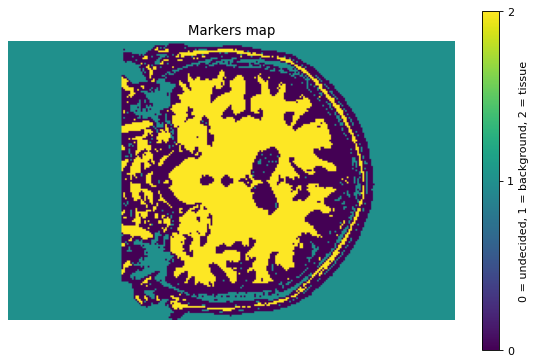

undecided / background / tissue fractions: [0.221 0.575 0.204]


In [23]:
#markers = np.zeros_like(img)
#markers[ img < ? ] = 1
#markers[img > ?] = 2

#plot the markers
# ANSWER (img_255 is used instead of "img", which already holds the NIfTI object)
markers = np.zeros_like(img_255, dtype=np.int32)
markers[img_255 < 10] = 1           # sure background (air, but also the darkest CSF)
markers[img_255 > 60] = 2           # sure bright tissue (mainly white matter, but also scalp fat)
plt.figure(figsize=(9, 5.5))
plt.imshow(markers, cmap="viridis"); plt.colorbar(ticks=[0, 1, 2], label="0 = undecided, 1 = background, 2 = tissue")
plt.title("Markers map"); plt.axis("off"); plt.show()
print("undecided / background / tissue fractions:", np.round([np.mean(markers == k) for k in range(3)], 3))

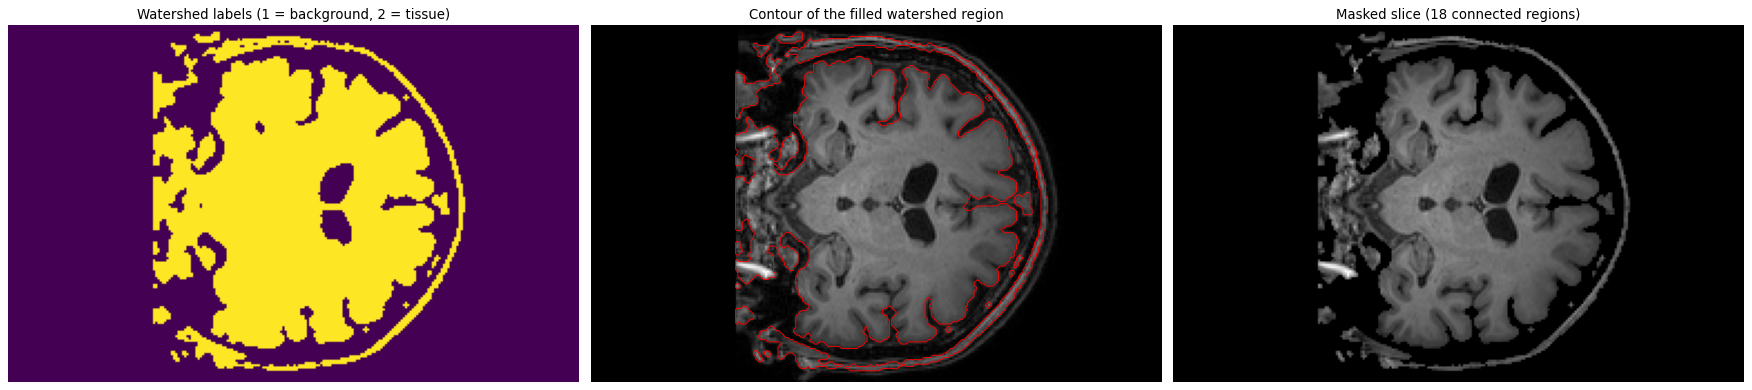

watershed region: 32.0% of the image | brain mask (bonus): 20.2% | Dice = 0.772


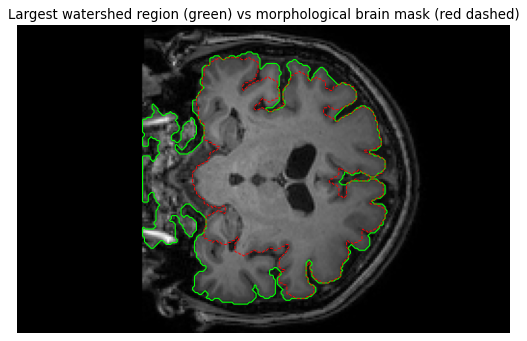

largest watershed region: 28.3% of the image | Dice with the morphological brain mask = 0.831


In [24]:
#segmentation_brain = ski.segmentation.watershed(elevation_map, markers)

#plot result
# ANSWER
segmentation_brain = ski.segmentation.watershed(elevation_map, markers)
segmentation_filled = ndimage.binary_fill_holes(segmentation_brain - 1)       # as in the coins example
labeled_regions, n_regions = ndimage.label(segmentation_filled)
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
axes[0].imshow(segmentation_brain, cmap="viridis"); axes[0].set_title("Watershed labels (1 = background, 2 = tissue)")
axes[1].imshow(slice_1, cmap="gray"); axes[1].contour(segmentation_filled, [0.5], colors="r", linewidths=0.8)
axes[1].set_title("Contour of the filled watershed region")
axes[2].imshow(np.where(segmentation_filled, slice_1, 0), cmap="gray"); axes[2].set_title(f"Masked slice ({n_regions} connected regions)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

# comparison with the morphological brain mask of section I
dice = 2 * np.sum(segmentation_filled & (brain_mask > 0)) / (segmentation_filled.sum() + (brain_mask > 0).sum())
print(f"watershed region: {segmentation_filled.mean():.1%} of the image | brain mask (bonus): {(brain_mask > 0).mean():.1%} | Dice = {dice:.3f}")

# post-processing: keep only the largest connected region (removes the scalp ring and the neck fragments)
sizes = ndimage.sum(segmentation_filled, labeled_regions, range(1, n_regions + 1))
ws_brain = labeled_regions == (1 + np.argmax(sizes))
dice2 = 2 * np.sum(ws_brain & (brain_mask > 0)) / (ws_brain.sum() + (brain_mask > 0).sum())
plt.figure(figsize=(8, 5)); plt.imshow(slice_1, cmap="gray"); plt.contour(ws_brain, [0.5], colors="lime", linewidths=1)
plt.contour(brain_mask > 0, [0.5], colors="r", linewidths=0.8, linestyles="--")
plt.title("Largest watershed region (green) vs morphological brain mask (red dashed)"); plt.axis("off"); plt.show()
print(f"largest watershed region: {ws_brain.mean():.1%} of the image | Dice with the morphological brain mask = {dice2:.3f}")

**ANSWER (interpretation of the watershed segmentation)**
- **Elevation map:** the Sobel gradient is high on tissue boundaries (scalp, skull, cortex/CSF, ventricles) and low inside homogeneous regions, so the watershed lines that separate basins follow the edges.
- **Markers** (from the histogram on the 0–255 scale):
  - < 10 → background (57.5 % of the pixels: air and the darkest CSF);
  - > 60 → tissue (20.4 %: mainly white matter, but also the bright scalp);
  - the remaining 22.1 % are undecided and are assigned by flooding the elevation map from the markers.
- **Result:**
  - The "tissue" label contains the brain, but also the scalp ring and fragments of the skull-base and neck tissues (32 % of the image, 18 connected regions after hole filling).
  - The dark skull/CSF layer acts as a barrier, so the scalp ends up as a separate region.
  - Keeping only the **largest connected region** gives a brain mask (28.3 % of the image) close to the morphological mask of Part I (**Dice = 0.831**). The two masks agree well along the cortex. The watershed mask leaks inferiorly into skull-base tissue and vessels, whose intensities and edges resemble those of the brain.
- **Assessment:** region-based segmentation uses edges and spatial connectivity rather than intensity alone, which makes it more robust than a plain threshold. It still depends on the marker thresholds, and it cannot separate structures with similar intensity when no strong edge lies between them.

Questions : 

1) In the provided watershed function, describe the role of the compactness parameter and how increasing it affects the segmentation.

2) What is the difference between connectivity=1 and connectivity=2 in 2D images, and how does it influence the resulting regions?

Hint : cf. https://github.com/scikit-image/scikit-image/blob/v0.25.2/skimage/segmentation/_watershed.py#L86-L242



compactness =  0.0000:     0 pixels change label, tissue region = 0.309 of the image
compactness =  0.0001:   682 pixels change label, tissue region = 0.314 of the image
compactness =  0.0010:   820 pixels change label, tissue region = 0.314 of the image
compactness =  0.0100:  1241 pixels change label, tissue region = 0.319 of the image
compactness =  0.1000:  1745 pixels change label, tissue region = 0.324 of the image
compactness =  1.0000:  1763 pixels change label, tissue region = 0.324 of the image


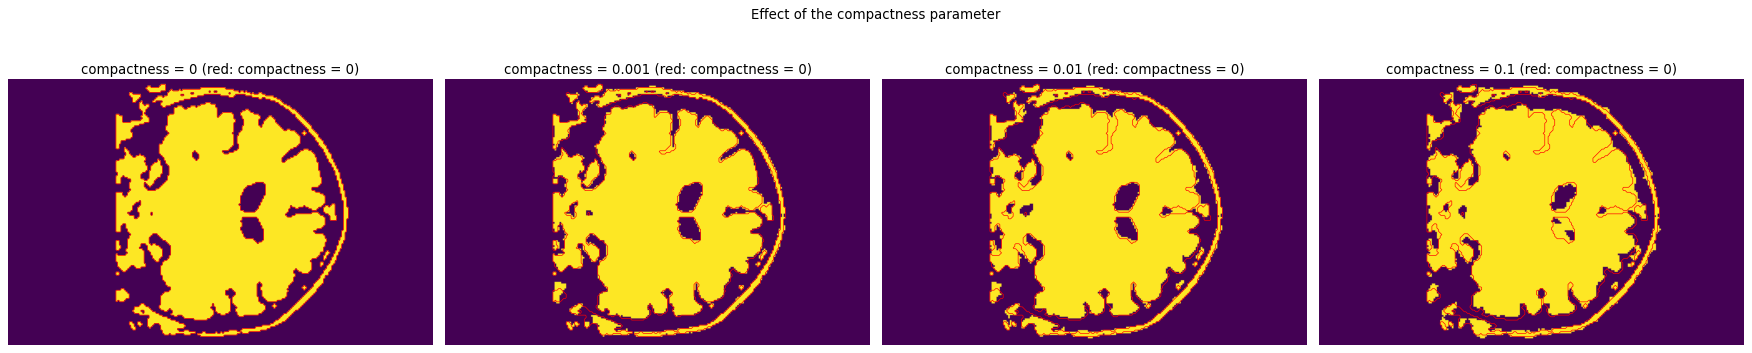

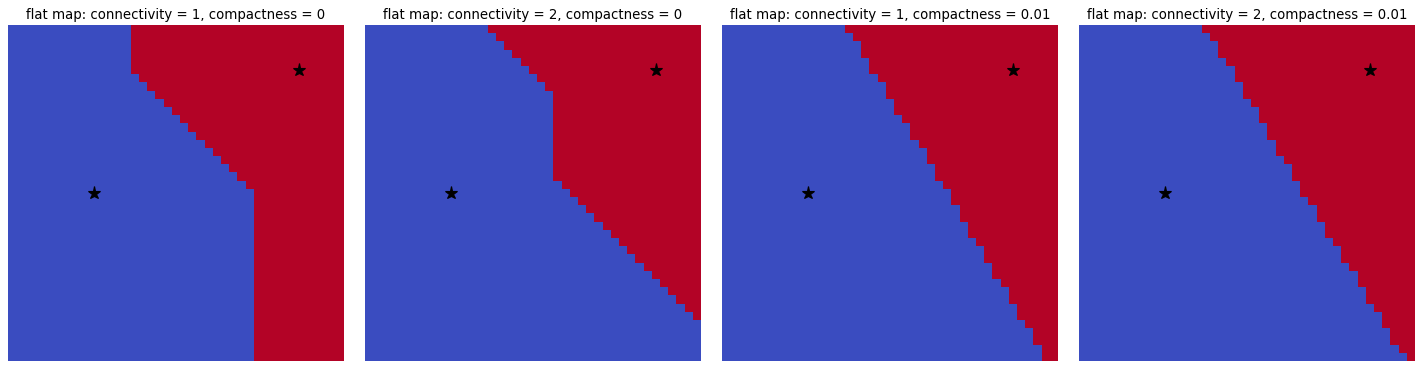


connectivity 1 vs 2: 818 pixels change label
watershed-line pixels: connectivity 1 = 1809, connectivity 2 = 2401
tissue components (8-connected count): conn=1 -> 17 | conn=2 -> 18
tissue components (4-connected count): conn=1 -> 18 | conn=2 -> 18


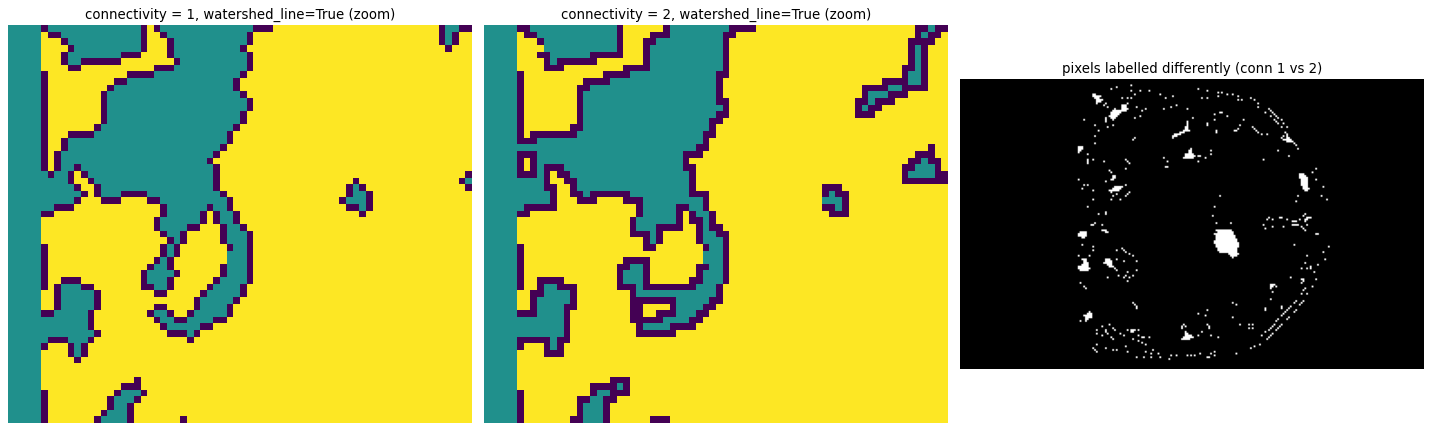

In [25]:
# ANSWER: experiments supporting the two questions (compactness and connectivity)
base = ski.segmentation.watershed(elevation_map, markers)
comp_values = [0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for c_ in comp_values:
    seg_c = ski.segmentation.watershed(elevation_map, markers, compactness=c_)
    print(f"compactness = {c_:7.4f}: {np.sum(seg_c != base):5d} pixels change label, tissue region = {np.mean(seg_c == 2):.3f} of the image")
for a, c_ in zip(axes, [0, 1e-3, 1e-2, 1e-1]):
    seg_c = ski.segmentation.watershed(elevation_map, markers, compactness=c_)
    a.imshow(seg_c, cmap="viridis"); a.contour(base, [1.5], colors="r", linewidths=0.6)
    a.set_title(f"compactness = {c_} (red: compactness = 0)"); a.axis("off")
plt.suptitle("Effect of the compactness parameter"); plt.tight_layout(); plt.show()

# Toy example: two markers on a flat elevation map -> regions governed only by the flooding rule / distance
toy = np.zeros((41, 41)); toy_m = np.zeros((41, 41), int); toy_m[20, 10] = 1; toy_m[5, 35] = 2
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for a, (conn, comp) in zip(axes, [(1, 0), (2, 0), (1, 0.01), (2, 0.01)]):
    a.imshow(ski.segmentation.watershed(toy, toy_m, connectivity=conn, compactness=comp), cmap="coolwarm")
    a.plot([10, 35], [20, 5], "k*", ms=12); a.set_title(f"flat map: connectivity = {conn}, compactness = {comp}"); a.axis("off")
plt.tight_layout(); plt.show()

# connectivity 1 (4-neighbourhood) vs 2 (8-neighbourhood) on the MRI slice
seg_c1 = ski.segmentation.watershed(elevation_map, markers, connectivity=1)
seg_c2 = ski.segmentation.watershed(elevation_map, markers, connectivity=2)
line_c1 = ski.segmentation.watershed(elevation_map, markers, connectivity=1, watershed_line=True)
line_c2 = ski.segmentation.watershed(elevation_map, markers, connectivity=2, watershed_line=True)
print(f"\nconnectivity 1 vs 2: {np.sum(seg_c1 != seg_c2)} pixels change label")
print(f"watershed-line pixels: connectivity 1 = {np.sum(line_c1 == 0)}, connectivity 2 = {np.sum(line_c2 == 0)}")
print("tissue components (8-connected count): conn=1 ->", ndimage.label(seg_c1 == 2, np.ones((3, 3)))[1],
      "| conn=2 ->", ndimage.label(seg_c2 == 2, np.ones((3, 3)))[1])
print("tissue components (4-connected count): conn=1 ->", ndimage.label(seg_c1 == 2)[1],
      "| conn=2 ->", ndimage.label(seg_c2 == 2)[1])
zoom = (slice(20, 80), slice(60, 130))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
axes[0].imshow(line_c1[zoom], cmap="viridis"); axes[0].set_title("connectivity = 1, watershed_line=True (zoom)")
axes[1].imshow(line_c2[zoom], cmap="viridis"); axes[1].set_title("connectivity = 2, watershed_line=True (zoom)")
axes[2].imshow((seg_c1 != seg_c2), cmap="gray"); axes[2].set_title("pixels labelled differently (conn 1 vs 2)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Answers : 

1. **ANSWER – Role of `compactness`.**
   - With `compactness = 0` (default), the classic watershed floods pixels in the order of their **elevation only**: a priority queue keyed on the elevation value, with ties broken by order of arrival. Basin boundaries therefore follow the crests of the elevation map (image edges) exactly, whatever the resulting shape. Regions can be very irregular, and they leak through weak or broken edges.
   - With `compactness = c > 0`, skimage uses the **compact watershed** (Neubert & Protzel, 2014). The priority of a pixel becomes elevation + c × (Euclidean distance between the pixel and the marker pixel its flooding started from). Pixels far from their marker are processed later, so each basin grows more **regularly**, more like a disk around its marker.
   - **Increasing compactness** gives more regular, compact, similarly sized regions with smoother boundaries, but **less adherence to the image edges**. For very large values the elevation map becomes negligible and the result tends to a **Voronoi partition** of the markers (each pixel goes to the nearest marker). What counts is c relative to the elevation values: here the Sobel map is ≤ 0.39 while distances are tens of pixels, so c = 0.01 is already strong.
   - **Experiment:**
     - the number of re-labelled pixels grows from 682 (c = 1e-4) to 1763 (c = 1), and the tissue label grows from 30.9 % to 32.4 % of the image;
     - at c ≥ 0.1 the tissue basin crosses weak edges and invades sulci and ventricles;
     - the effect saturates because the markers already cover 78 % of the image, so only the 22 % undecided pixels can change;
     - on a flat elevation map (toy example) the boundary becomes the straight perpendicular bisector between the two markers (Euclidean Voronoi).
   - **When to use it:** compactness is useful to produce regular superpixels. For anatomical segmentation, `compactness = 0` (or very small) is preferable so that the boundaries follow the real edges.

2. **ANSWER – `connectivity = 1` vs `connectivity = 2` in 2D.**
   - The connectivity defines which pixels are **neighbours** during flooding: the maximum number of orthogonal steps to reach a neighbour, as in `scipy.ndimage.generate_binary_structure`.
     - `connectivity = 1` → **4-neighbourhood**: the pixels sharing an edge (up, down, left, right). This is the skimage default.
     - `connectivity = 2` → **8-neighbourhood**: the 4 above plus the 4 diagonal pixels.
   - **Influence on the regions:**
     - **Propagation:** with 8-connectivity a basin can flood through diagonal contacts. A one-pixel-wide diagonal crest of the elevation map no longer stops it, so regions can leak through thin diagonal gaps, and thin diagonal structures stay connected. With 4-connectivity, a diagonal line of high elevation is enough to block the flooding.
     - **Shape of the fronts on plateaus:** 4-connected flooding grows diamond-shaped fronts (city-block distance), 8-connected flooding grows square fronts (chessboard distance). Boundaries inside flat or ambiguous areas are therefore placed differently, as the flat-map toy example shows.
     - **Watershed lines** (`watershed_line=True`): to separate two regions, the line must block every neighbour relation. With 8-connectivity the lines are thicker (2401 vs 1809 line pixels here); 4-connected lines are thinner, but the regions on each side may touch diagonally.
   - **On our slice:** 818 pixels (2.0 % of the image) change label between the two settings. They lie mostly along boundaries in the undecided zone between the markers, plus one region near the midline between the ventricles. The number of tissue components is similar (17–18). The choice of connectivity should also be consistent with the one used afterwards to label the regions (e.g. `ndimage.label`).